In [1]:
import scanpy as sc
import pandas as pd
import anndata as ad
import harmonypy as hmå
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pilotpy.tools import *  #scvi env
from pilotpy.plot import *
import scanpy as sc
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd
import harmonypy as hm
import os
desired_path = '/beegfs//data/CostaLab/spatial_kidney_kuppelab/Adenin/HE/' # Or the folder your current notebook is in
os.chdir(desired_path)

### All his include humna.mouse for adenin

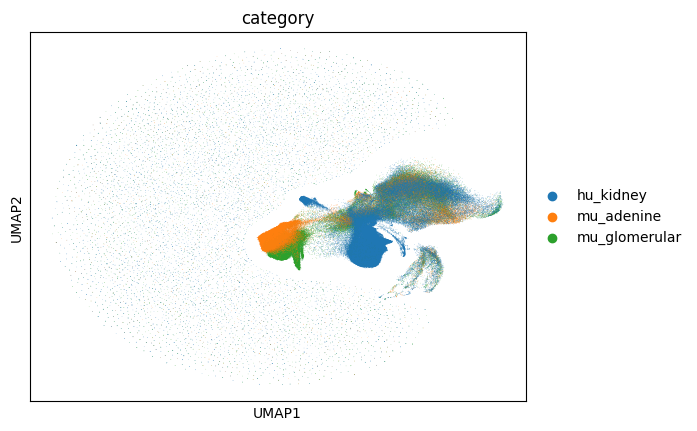

In [ ]:
#adata=sc.read_h5ad('/beegfs/data/CostaLab/spatial_kidney_kuppelab/Human_mouse_all_xenium/all_his.h5ad')


#adata.obs['Slide_ID_clean'] = adata.obs['Slide_ID'].astype(str).str.replace('f$', '', regex=True)

#mapping = pd.read_csv('/beegfs/data/CostaLab/spatial_kidney_kuppelab/Human_mouse_all_xenium/mapping.csv', sep=';')
#mapping['Slide_ID'] = mapping['xenium_slide'].astype(str) + '-' + mapping['xenium_region'].astype(str)

#mapping_unique = mapping.drop_duplicates(subset='Slide_ID', keep='first')
#sample_dict = dict(zip(mapping_unique['Slide_ID'], mapping_unique['sample_ID']))
#category_dict = dict(zip(mapping_unique['Slide_ID'], mapping_unique['category']))

#adata.obs['sample_ID'] = adata.obs['Slide_ID_clean'].astype(str).map(sample_dict)
#adata.obs['category'] = adata.obs['Slide_ID_clean'].astype(str).map(category_dict)

#ho = hm.run_harmony(adata.obsm["X_pca"], adata_human_mouse.obs, ["category"])
#adata.obsm["X_pca_harmony"] = ho.Z_corr
#sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca_harmony")
#sc.tl.leiden(adata, resolution=0.00001)
#sc.pl.umap(adata,color='category')

In [ ]:
#adata=sc.read_h5ad('/beegfs/data/CostaLab/spatial_kidney_kuppelab/Human_mouse_all_xenium/all_his.h5ad')

#### Mouse

In [ ]:
adata=sc.read_h5ad('adenin_his_v2.h5ad')
adata.obs['Donor_key'] = adata.obs['Slide_ID'].astype(str).str.split('_').str[0]

In [ ]:
#adata.write_h5ad('adenin_his_v2.h5ad')

In [51]:
spatial_data=sc.read_h5ad('mu_all.h5ad')
spatial_data=spatial_data[spatial_data.obs['category'].isin(['adenine_recovery_model'])].copy()
donor_group = spatial_data.obs.drop_duplicates(subset='Donor')
group_dict = dict(zip(donor_group['Donor'].astype(str), donor_group['group'].astype(str)))
adata.obs['group'] = adata.obs['Donor_key'].map(group_dict)

In [ ]:

#adata=adata[adata.obs['leiden_01'].isin(['0','3'])].copy()   #for adenin_his.h5ad


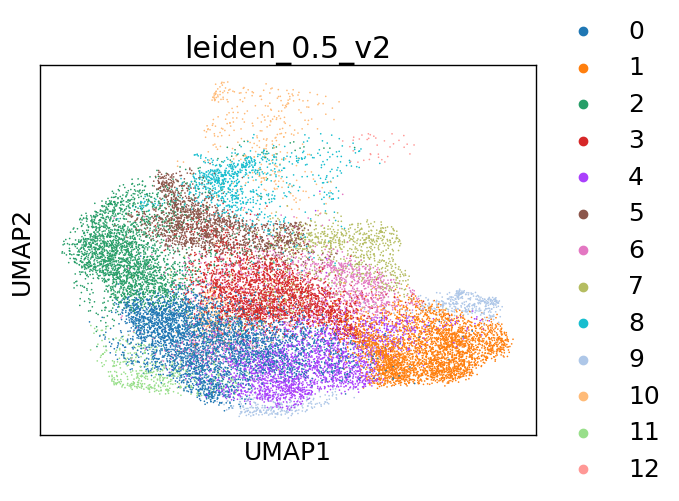

In [109]:
sc.pl.umap(adata, color=['leiden_0.5_v2']) 

Text(0.5, 1.0, 'UMAP with 10 Example Patches per Cluster')

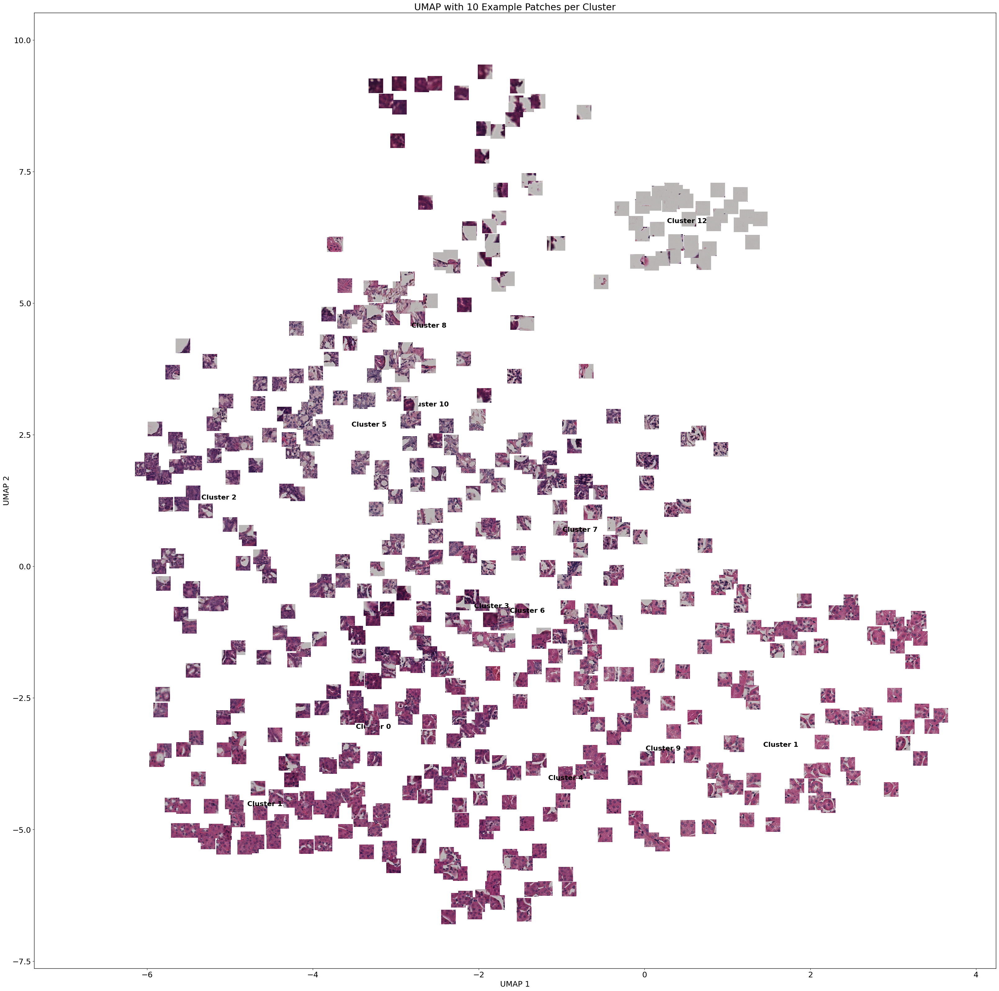

In [108]:
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import seaborn as sns
import random

# **Step 1: Extract UMAP Coordinates**
umap_coords = adata.obsm["X_umap"]
clusters = adata.obs["leiden_0.5_v2"].astype(str)  # Convert Leiden clusters to strings
sample_ids = adata.obs["Slide_ID"].astype(str)  # Get patient/sample IDs
patch_ids = adata.obs["Patch_ID_x"].astype(str)  # Get patch file names

# **Step 2: Define Base Patch Folder**
patch_base_folder = "output_patches/"

# **Step 3: Function to Load Patch Images**
def getImage(path, zoom=0.15):  # Adjust zoom level for patch size
    return OffsetImage(plt.imread(path), zoom=zoom)

# **Step 4: Create UMAP Scatter Plot**
fig, ax = plt.subplots(figsize=(40, 40))
ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c="white", alpha=1, edgecolors="w", label="Cells")

# **Step 5: Process Each Cluster**
for cluster in sorted(clusters.unique()):
    # **Select 10 Random Points for this Cluster**
    cluster_indices = np.where(clusters == cluster)[0]
    if len(cluster_indices) == 0:
        continue

    selected_indices = random.sample(list(cluster_indices), min(50, len(cluster_indices)))

    # **Step 6: Overlay Patch Images**
    for i in selected_indices:
        x0, y0 = umap_coords[i]  # Get UMAP position
        sample_id = sample_ids[i]  # Get Sample ID
        patch_id = patch_ids[i]  # Get Patch file name

        # **Construct Patch Path**
        patch_folder = os.path.join(patch_base_folder, sample_id)
        patch_path = os.path.join(patch_folder, patch_id)

        if not os.path.exists(patch_path):
            print(f"Warning: Missing patch {patch_path}")
            continue

        # **Step 7: Add Patch to UMAP**
        ab = AnnotationBbox(getImage(patch_path), (x0, y0), frameon=False, box_alignment=(0.5, 0.5), pad=0)
        ax.add_artist(ab)

    # **Step 8: Annotate Cluster**
    avg_x, avg_y = np.mean(umap_coords[cluster_indices], axis=0)
    ax.annotate(f"Cluster {cluster}", (avg_x, avg_y), fontsize=16, ha="center", color="black", weight="bold")

# **Step 9: Finalize & Show Plot**
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP with 10 Example Patches per Cluster")
#fig.savefig('Results_PILOT/Umap_patches.pdf')

In [56]:
import numpy as np

def flag_edge_patches(adata, sample_col="Sample_ID", x_col="X", y_col="Y", edge_fraction=0.7):
    is_edge = np.zeros(adata.n_obs, dtype=bool)
    for sample in adata.obs[sample_col].unique():
        mask = (adata.obs[sample_col] == sample).values
        x = adata.obs.loc[mask, x_col].values.astype(float)
        y = adata.obs.loc[mask, y_col].values.astype(float)
        cx, cy = x.mean(), y.mean()
        r = np.sqrt((x - cx) ** 2 + (y - cy) ** 2)
        is_edge[mask] = r > (edge_fraction * r.max())
    return is_edge

adata.obs["is_edge_patch"] = flag_edge_patches(adata)
adata = adata[adata.obs['is_edge_patch'] == False].copy()

In [ ]:
#sc.tl.leiden(adata, resolution=0.2, key_added="leiden_0.01_v2")
#sc.tl.leiden(adata, resolution=0.3, key_added="leiden_0.3_v2")
#sc.tl.leiden(adata, resolution=0.4, key_added="leiden_0.4_v2")
#sc.tl.leiden(adata, resolution=0.5, key_added="leiden_0.5_v2")
#sc.tl.leiden(adata, resolution=0.6, key_added="leiden_0.6_v2")

In [ ]:
#adata=adata[adata.obs['leiden_0.01_v2'].isin(['0','2','3','4','1'])].copy()  

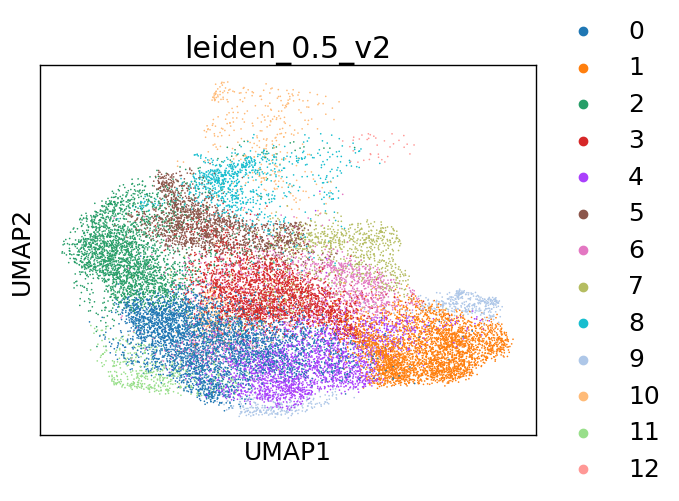

In [107]:
sc.pl.umap(adata, color=['leiden_0.5_v2']) 

In [106]:
#sc.tl.leiden(adata, resolution=0.5, key_added="leiden_0.5_v2")

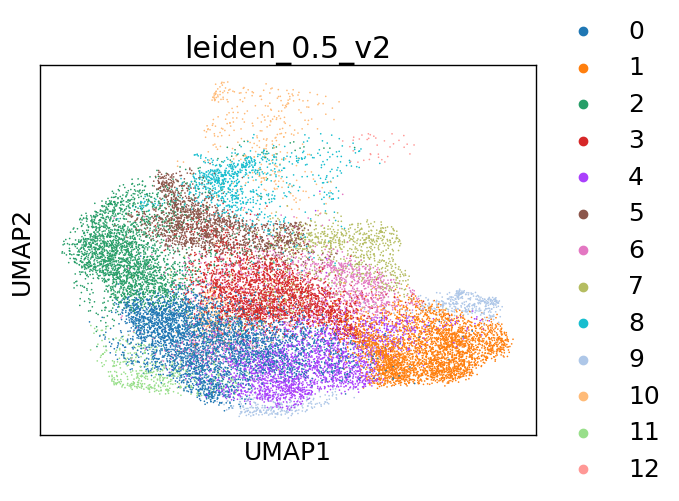

In [92]:
sc.pl.umap(adata, color=['leiden_0.5_v2']) 

In [ ]:
#adata.obs['leiden_0.2_v2'].unique()

['0', '1', '2', '3', '4', ..., '46', '47', '48', '49', '9']
Length: 50
Categories (50, object): ['0', '1', '2', '3', ..., '46', '47', '48', '49']

Saved 22 core plots to plots_cores_leiden05/


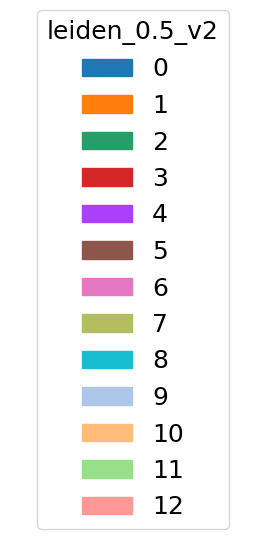

In [94]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle

patch_size = 224  # pixels, patches are patch_size x patch_size

output_dir = "plots_cores_leiden05"
os.makedirs(output_dir, exist_ok=True)

# **Color mapping for leiden_04 clusters (reuse scanpy's colors if already computed)**
cluster_col = "leiden_0.5_v2"
categories = adata.obs[cluster_col].cat.categories
uns_key = f"{cluster_col}_colors"
if uns_key in adata.uns:
    palette = adata.uns[uns_key]
else:
    cmap = plt.get_cmap("tab20", len(categories))
    palette = [cmap(i) for i in range(len(categories))]
color_map = dict(zip(categories, palette))

# **Plot one figure per core (Slide_ID), patches drawn at their true X,Y location/size — no legend**
for slide_id in adata.obs["Slide_ID"].unique():
    sub = adata.obs[adata.obs["Slide_ID"] == slide_id]
    donor_key = sub["Donor_key"].iloc[0]
    group = sub["group"].iloc[0]

    fig, ax = plt.subplots(figsize=(12, 12))

    rects = [
        Rectangle((x - patch_size / 2, y - patch_size / 2), patch_size, patch_size)
        for x, y in zip(sub["X"], sub["Y"])
    ]
    colors = [color_map[c] for c in sub[cluster_col]]
    ax.add_collection(PatchCollection(rects, facecolor=colors, edgecolor="none"))

    ax.set_xlim(sub["X"].min() - patch_size, sub["X"].max() + patch_size)
    ax.set_ylim(sub["Y"].min() - patch_size, sub["Y"].max() + patch_size)
    ax.invert_yaxis()  # image-style coordinates: Y grows downward
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{donor_key}_{group}  (n={len(sub)} patches)")

    fig.tight_layout()
    fig.savefig(os.path.join(output_dir, f"{donor_key}_{group}.png"), dpi=200, bbox_inches="tight")
    plt.close(fig)

print(f"Saved {adata.obs['Slide_ID'].nunique()} core plots to {output_dir}/")

# **Plot the leiden_04 color legend separately (one shared legend for all cores)**
fig, ax = plt.subplots(figsize=(3, len(categories) * 0.3))
legend_handles = [mpatches.Patch(color=color_map[c], label=c) for c in categories]
ax.legend(handles=legend_handles, title=cluster_col, loc="center")
ax.axis("off")
fig.tight_layout()
fig.savefig("/beegfs/data/CostaLab/spatial_kidney_kuppelab/Adenin/HE/plots_cores_leiden05/legend.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
import os
from PIL import Image

# **Reassemble each core from its real saved patches (puzzle), placed at their true X,Y**
patch_size = 224
patch_base_folder = "output_patches/"
output_dir_real = "cores_real_patches"
os.makedirs(output_dir_real, exist_ok=True)

for slide_id in adata.obs["Slide_ID"].unique():
    sub = adata.obs[adata.obs["Slide_ID"] == slide_id]

    # top-left corner of each patch (X,Y are patch centers)
    left = sub["X"] - patch_size / 2
    top = sub["Y"] - patch_size / 2

    canvas_x0, canvas_y0 = left.min(), top.min()
    canvas_w = int(left.max() + patch_size - canvas_x0)
    canvas_h = int(top.max() + patch_size - canvas_y0)

    canvas = Image.new("RGB", (canvas_w, canvas_h), color=(255, 255, 255))

    patch_folder = os.path.join(patch_base_folder, str(slide_id))
    n_missing = 0

    for _, row in sub.iterrows():
        patch_path = os.path.join(patch_folder, str(row["Patch_ID_x"]))
        if not os.path.exists(patch_path):
            n_missing += 1
            continue

        patch_img = Image.open(patch_path).convert("RGB")
        if patch_img.size != (patch_size, patch_size):
            patch_img = patch_img.resize((patch_size, patch_size))

        px = int(row["X"] - patch_size / 2 - canvas_x0)
        py = int(row["Y"] - patch_size / 2 - canvas_y0)
        canvas.paste(patch_img, (px, py))

    canvas.save(os.path.join(output_dir_real, f"{slide_id}.png"))
    print(f"{slide_id}: saved {canvas.size} mosaic, {len(sub)} patches, {n_missing} missing")

## Mouse His

In [95]:
adata.obs['sample_']=adata.obs['Donor_key'].astype(str)+'_'+adata.obs['group'].astype(str)

In [96]:
wasserstein_distance(adata,emb_matrix='X_pca',
clusters_col='leiden_0.5_v2',sample_col='sample_',status='group',metric='euclidean')

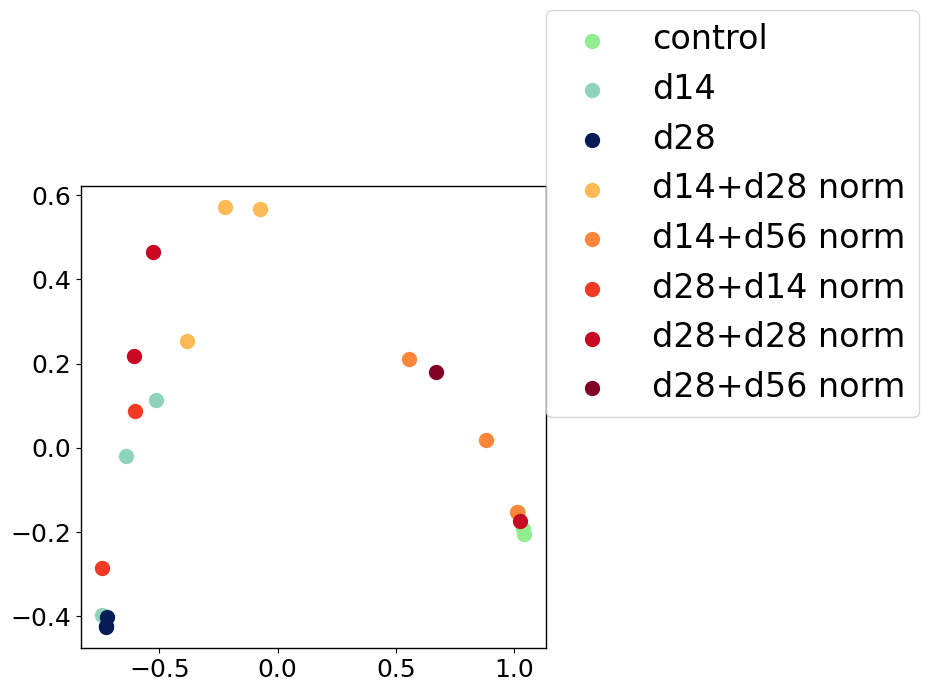

In [98]:
import numpy as np
import matplotlib.cm as cm
import matplotlib.colors as mcolors

legend_order = ['control','d14', 'd28', 'd14+d28 norm','d14+d56 norm',  'd28+d14 norm','d28+d28 norm', 'd28+d56 norm', 
                 ]

disease_categories = ['d14', 'd28']
recovery_categories = ['d14+d28 norm', 'd14+d56 norm', 'd28+d14 norm', 'd28+d28 norm', 'd28+d56 norm']
control_color = 'lightgreen'

def sample_cmap(name, n, vmin=0.35, vmax=1.0):
    cmap = cm.get_cmap(name)
    return [mcolors.to_hex(cmap(v)) for v in np.linspace(vmin, vmax, n)]

disease_colors = dict(zip(disease_categories, sample_cmap('YlGnBu', len(disease_categories))))
recovery_colors = dict(zip(recovery_categories, sample_cmap('YlOrRd', len(recovery_categories))))

color_map = {'control': control_color, **disease_colors, **recovery_colors}
colors = [color_map[cat] for cat in legend_order]


trajectory(adata, colors=colors, label_act=False, font_size=18, knn=8, figsize=(6,6),
           legend_order=legend_order, location_labels=(1, 0.5))


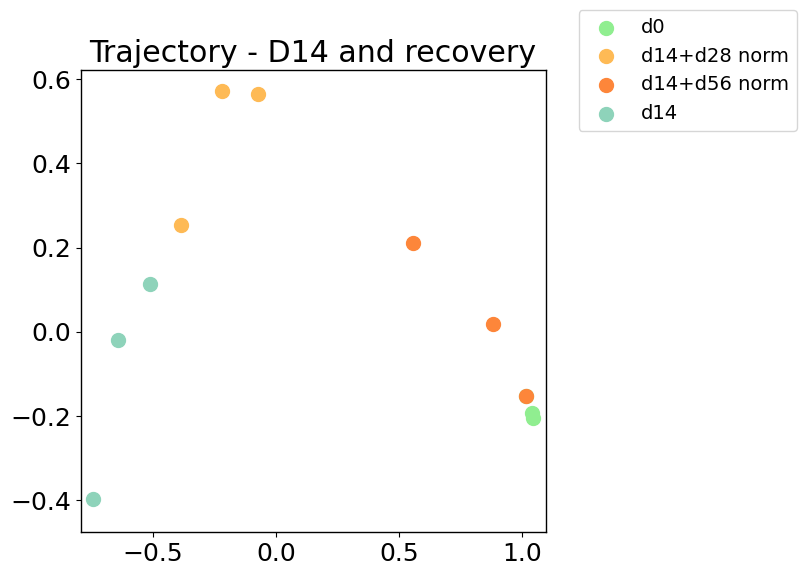

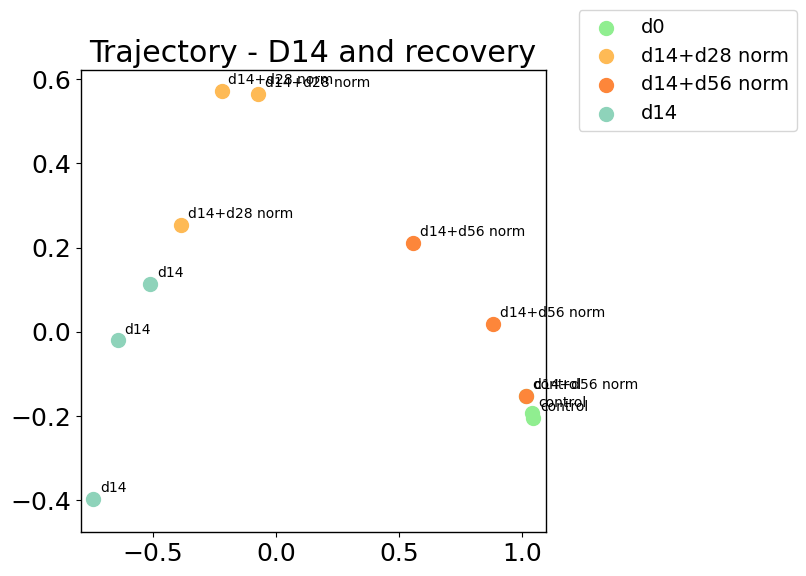

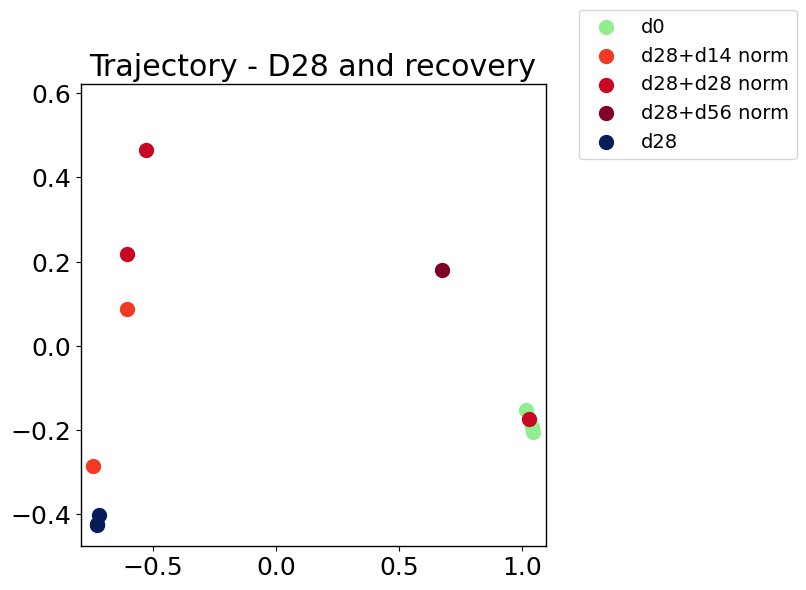

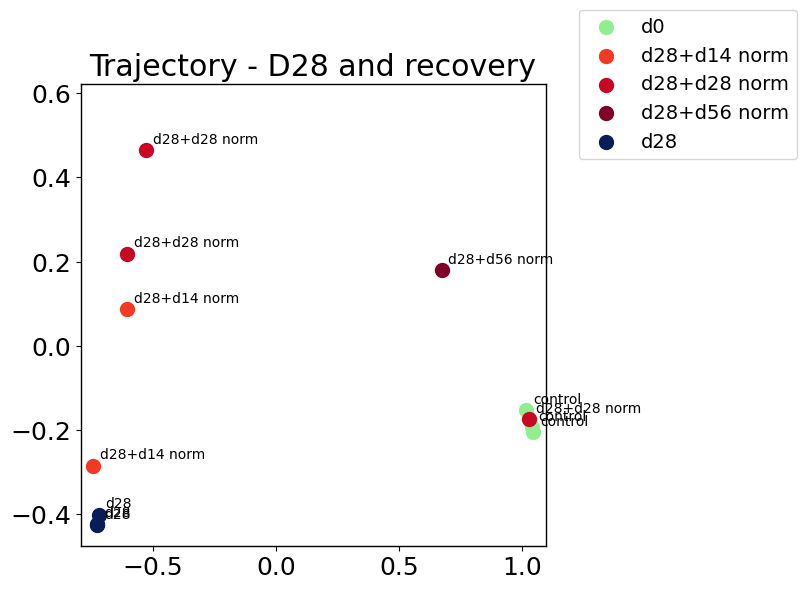

In [99]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42  # same fix if you ever export .eps/.ps


def plot_trajectory_subset(adata, categories, colors_map, title, path_img,
                            clusters='status', sample_col=1,
                            figsize=(6, 6), font_size=18, point_size=100,
                            fontsize_legend=14, location_labels='best',
                            xlim=None, ylim=None,
                            show_labels=False, label_col='sampleID', label_fontsize=10,
                            display_labels=None,
                            legend_outside=False, bbox_to_anchor=(1.05, 1)):
    if display_labels is None:
        display_labels = {}

    df = adata.uns['annot'].drop_duplicates(subset=[adata.uns['annot'].columns[sample_col]])
    embedding = adata.uns['embedding']

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_facecolor('white')
    plt.rcParams.update({'font.size': font_size})

    handles, labels = [], []
    for cat in categories:
        aux = np.array(df[clusters] == cat)
        group_data = embedding[aux]
        if len(group_data) == 0:
            continue
        scatter = ax.scatter(group_data[:, 0], group_data[:, 1],
                              color=colors_map[cat], s=point_size, label=cat)
        handles.append(scatter)
        labels.append(display_labels.get(cat, cat))

        if show_labels:
            point_labels = df.loc[aux, label_col].values
            for (x, y), txt in zip(group_data, point_labels):
                ax.annotate(str(txt), (x, y), fontsize=label_fontsize,
                            xytext=(5, 5), textcoords='offset points')

    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)

    if legend_outside:
        ax.legend(handles, labels, fontsize=fontsize_legend,
                  loc='center left', bbox_to_anchor=bbox_to_anchor)
    else:
        ax.legend(handles, labels, fontsize=fontsize_legend, loc=location_labels)

    ax.set_title(title)

    os.makedirs(os.path.dirname(path_img), exist_ok=True)
    plt.savefig(path_img, bbox_inches='tight')
    plt.show()
    plt.close(fig)



# shared axis limits so both plots are on the same scale
margin = 0.05
xlim = (adata.uns['embedding'][:, 0].min() - margin, adata.uns['embedding'][:, 0].max() + margin)
ylim = (adata.uns['embedding'][:, 1].min() - margin, adata.uns['embedding'][:, 1].max() + margin)

d14_categories = ['control', 'd14+d28 norm', 'd14+d56 norm', 'd14']
d28_categories = ['control', 'd28+d14 norm', 'd28+d28 norm', 'd28+d56 norm', 'd28']

display_labels = {'control': 'd0'}

base_dir = '/beegfs/data/CostaLab/spatial_kidney_kuppelab/Adenin/HE/Results_PILOT/plots/His'

for cats, name in [(d14_categories, 'd14'), (d28_categories, 'd28')]:
    # without point labels
    plot_trajectory_subset(adata, cats, color_map,
                            title=f"Trajectory - {name.upper()} and recovery",
                            path_img=f'{base_dir}/Trajectory_{name}_recovery.pdf',
                            xlim=xlim, ylim=ylim, show_labels=False,
                            display_labels=display_labels, legend_outside=True)

    # with point labels (sampleID beside each point)
    plot_trajectory_subset(adata, cats, color_map,
                            title=f"Trajectory - {name.upper()} and recovery",
                            path_img=f'{base_dir}/Trajectory_{name}_recovery_labeled.pdf',
                            xlim=xlim, ylim=ylim, show_labels=True, label_col='status',
                            display_labels=display_labels, legend_outside=True)


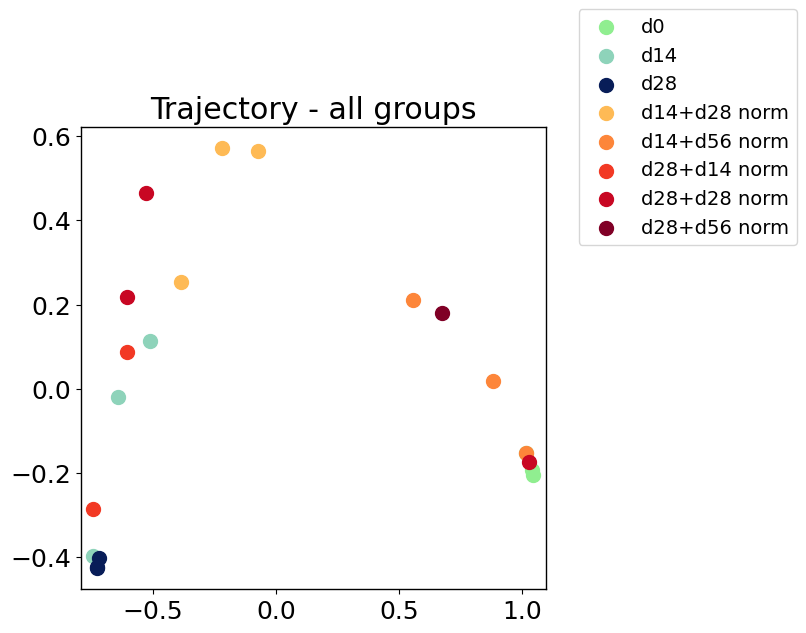

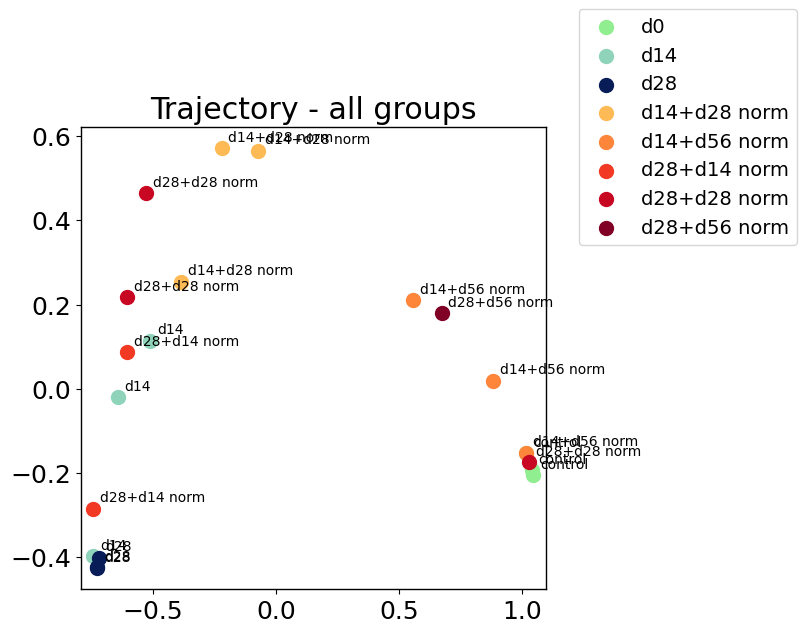

In [100]:
all_categories = ['control','d14','d28', 'd14+d28 norm', 'd14+d56 norm', 
                   'd28+d14 norm', 'd28+d28 norm', 'd28+d56 norm', ]

plot_trajectory_subset(adata, all_categories, color_map,
                        title="Trajectory - all groups",
                        path_img=f'{base_dir}/Trajectory_all_recovery.pdf',
                        xlim=xlim, ylim=ylim, show_labels=False,
                        display_labels=display_labels, legend_outside=True)

# labeled version
plot_trajectory_subset(adata, all_categories, color_map,
                        title="Trajectory - all groups",
                        path_img=f'{base_dir}/Trajectory_all_recovery_labeled.pdf',
                        xlim=xlim, ylim=ylim, show_labels=True, label_col='status',
                        display_labels=display_labels, legend_outside=True)


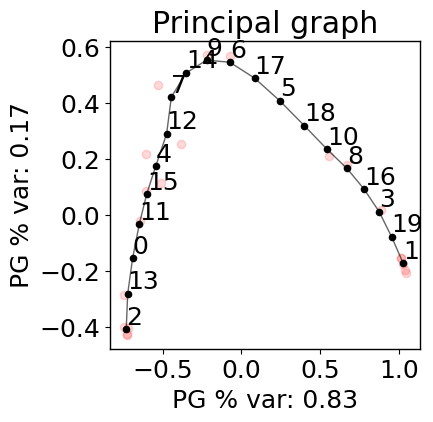

In [102]:

fit_pricipla_graph(adata, source_node =2,figsize=(4,4))

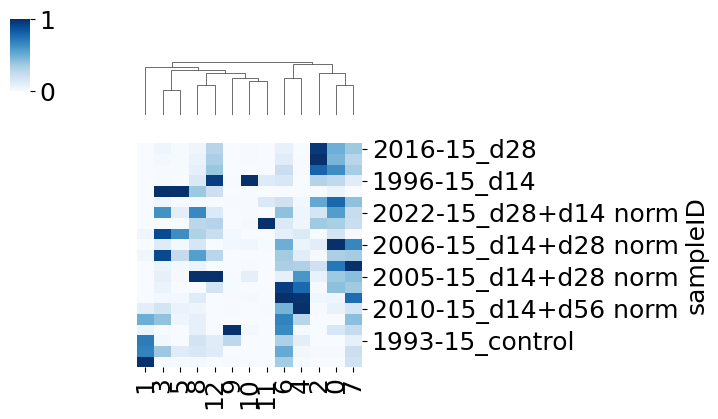

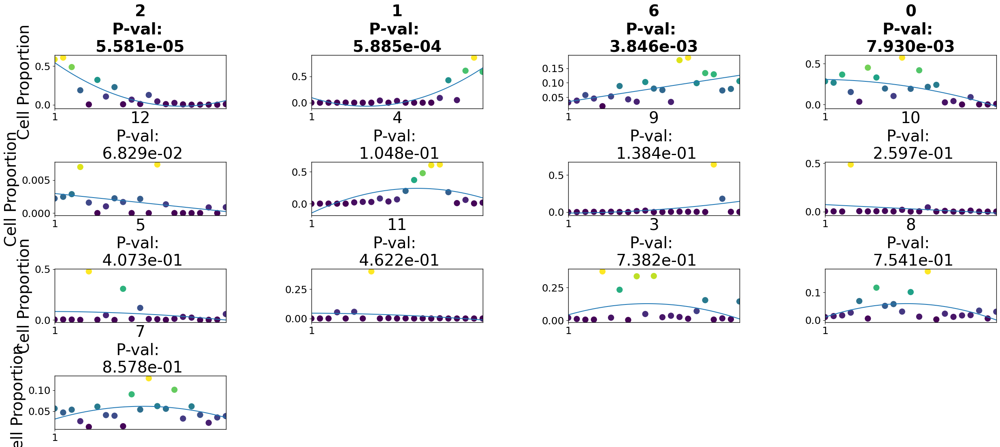

In [103]:
cell_importance(adata,height=12,width=30,fontsize=28,xlim=20,figsize=(4,4))

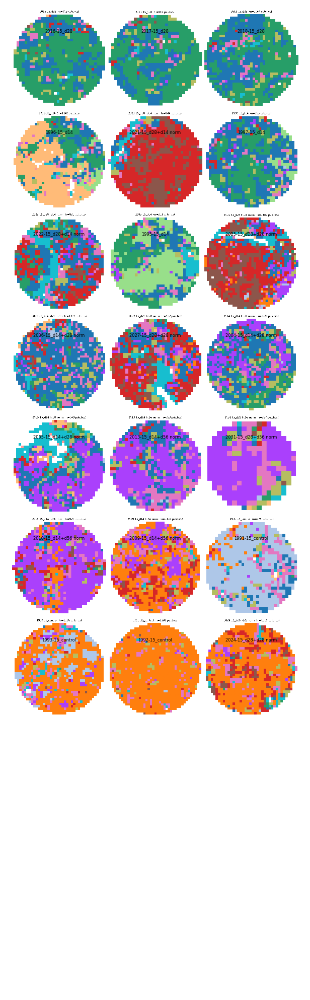

Saved grid to Results_PILOT/Cores_Patche_ordered.pdf


In [104]:
adata.uns['orders'].rename(columns={'Time_score': 'pseudotime'}, inplace=True)
create_sample_grid(df=adata.uns['orders'],image_dir='plots_cores_leiden05/', output_path="Results_PILOT/Cores_Patche_ordered.pdf",zoom=0.06)

In [111]:
adata.uns['EMD_df'].to_csv('hist_adenine_emd.csv')

Text(0.5, 1.0, 'UMAP with 10 Example Patches per Cluster')

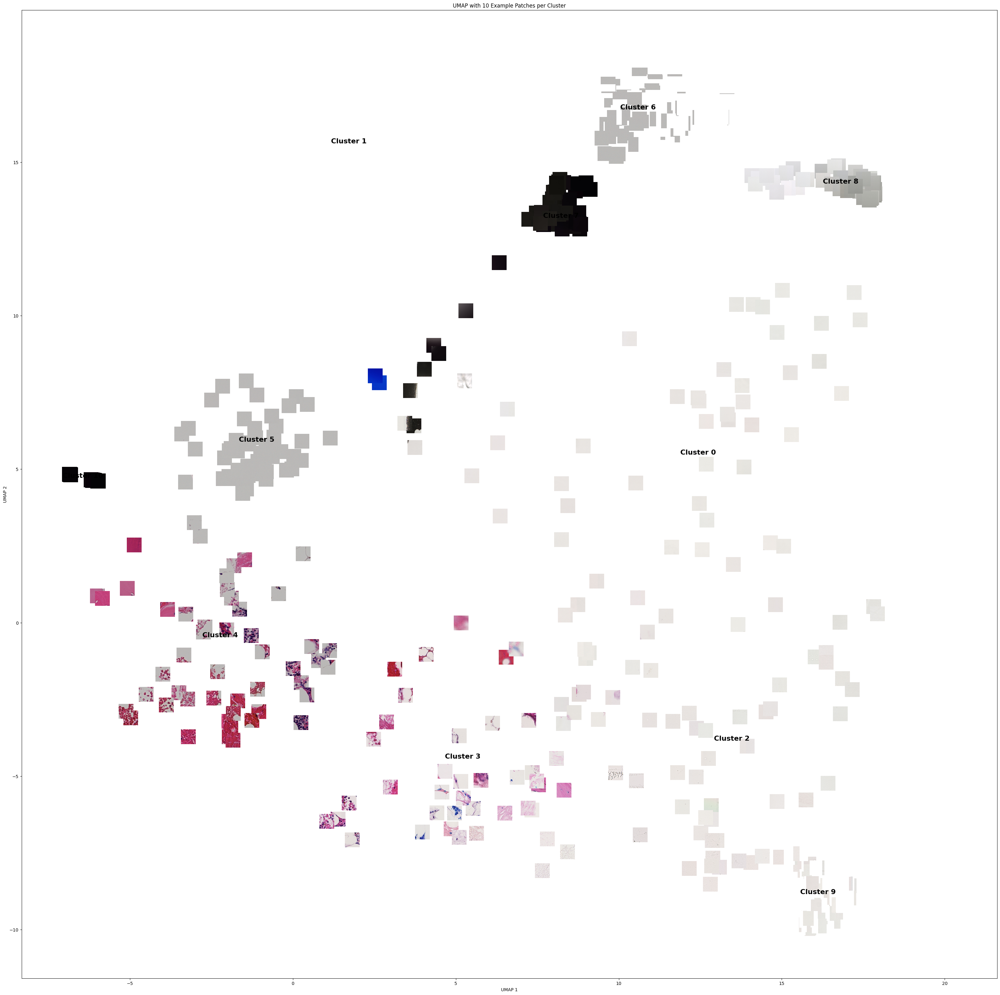

In [ ]:
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import seaborn as sns
import random

# **Step 1: Extract UMAP Coordinates**
umap_coords = adata.obsm["X_umap"]
clusters = adata.obs["leiden_0.1"].astype(str)  # Convert Leiden clusters to strings
sample_ids = adata.obs["Sample_ID"].astype(str)  # Get patient/sample IDs
patch_ids = adata.obs["Patch_ID"].astype(str)  # Get patch file names
batches = adata.obs["Dataset"].astype(str)  # Get patient/sample IDs
# **Step 2: Define Base Patch Folder**
patch_base_folder1 = "/beegfs/data/CostaLab/spatial_kidney_kuppelab/bbb/Bon_marrow/patchs/"
patch_base_folder2='/beegfs/data/CostaLab/spatial_kidney_kuppelab/bbb/bone_marow_new_37/New_35_samples/patchs'
# **Step 3: Function to Load Patch Images**
def getImage(path, zoom=0.15):  # Adjust zoom level for patch size
    return OffsetImage(plt.imread(path), zoom=zoom)

# **Step 4: Create UMAP Scatter Plot**
fig, ax = plt.subplots(figsize=(40, 40))
ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c="white", alpha=1, edgecolors="w", label="Cells")

# **Step 5: Process Each Cluster**
for cluster in sorted(clusters.unique()):
    # **Select 10 Random Points for this Cluster**
    cluster_indices = np.where(clusters == cluster)[0]
    if len(cluster_indices) == 0:
        continue

    selected_indices = random.sample(list(cluster_indices), min(50, len(cluster_indices)))

    # **Step 6: Overlay Patch Images**
    for i in selected_indices:
        x0, y0 = umap_coords[i]  # Get UMAP position
        sample_id = sample_ids[i]  # Get Sample ID
        patch_id = patch_ids[i]  # Get Patch file name
        batch=batches[i]
        # **Construct Patch Path**
        if batch=='37':
            patch_base_folder=patch_base_folder2
        else:
            patch_base_folder=patch_base_folder1

        patch_folder = os.path.join(patch_base_folder, sample_id)
        patch_path = os.path.join(patch_folder, patch_id)

        if not os.path.exists(patch_path):
            print(f"Warning: Missing patch {patch_path}")
            continue

        # **Step 7: Add Patch to UMAP**
        ab = AnnotationBbox(getImage(patch_path), (x0, y0), frameon=False, box_alignment=(0.5, 0.5), pad=0)
        ax.add_artist(ab)

    # **Step 8: Annotate Cluster**
    avg_x, avg_y = np.mean(umap_coords[cluster_indices], axis=0)
    ax.annotate(f"Cluster {cluster}", (avg_x, avg_y), fontsize=16, ha="center", color="black", weight="bold")

# **Step 9: Finalize & Show Plot**
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP with 10 Example Patches per Cluster")
#fig.savefig('Results_PILOT/Umap_patches.pdf')

In [48]:
!pwd

/beegfs/data/CostaLab/spatial_kidney_kuppelab/Adenin/HE


## Mouse Transcriptomics

In [24]:
spatial_data=sc.read_h5ad('mu_all.h5ad')
spatial_data=spatial_data[spatial_data.obs['category'].isin(['adenine_recovery_model'])].copy()

In [25]:
spatial_data.obs['sample_']=spatial_data.obs['Donor'].astype(str)+'_'+spatial_data.obs['group'].astype(str)

In [26]:
spatial_data.obs['Donor'].unique()

['2021-15', '1993-15', '1995-15', '2027-15', '1992-15', ..., '2018-15', '2025-15', '2024-15', '2022-15', '2031-15']
Length: 21
Categories (21, object): ['1991-15', '1992-15', '1993-15', '1995-15', ..., '2024-15', '2025-15', '2027-15', '2031-15']

In [27]:
import os
import glob
import numpy as np
import pandas as pd

base_dir = "/beegfs/data/CostaLab/spatial_kidney_kuppelab/Human_mouse_all_xenium"

mapping = pd.read_csv(os.path.join(base_dir, "mapping.csv"), sep=';')
# sample_ID_1 in spatial_data.obs is the cleaned form (e.g. "T16-02083"),
# while mapping's sample_ID keeps the raw suffix (e.g. "T16-02083 1G") — match on the stripped prefix
mapping['sample_ID_clean'] = mapping['sample_ID'].str.split(' ').str[0]

def get_batch_folder(coscine_path):
    # coscine_path e.g. "Xenium_2023/20240711__090235__20240709-11-12-X-VK/output-..."
    return coscine_path.split('/')[1]

def find_transform_matrix_path(xenium_slide, xenium_region, batch_folder):
    transforms_dir = os.path.join(base_dir, "transforms", batch_folder)
    pattern = os.path.join(transforms_dir, f"{xenium_slide}-{xenium_region}__*_R1.csv")
    matches = glob.glob(pattern)
    if len(matches) == 1:
        return matches[0]
    elif len(matches) > 1:
        print(f"Warning: multiple transform files match {pattern}: {matches}")
        return matches[0]
    else:
        print(f"Warning: no transform file found for {pattern}")
        return None

def transform_points(x, y, matrix):
    a, b, xoff = matrix[0, 0], matrix[0, 1], matrix[0, 2]
    d, e, yoff = matrix[1, 0], matrix[1, 1], matrix[1, 2]
    x_new = a * x + b * y + xoff
    y_new = d * x + e * y + yoff
    return x_new, y_new

spatial_transformed = np.full_like(spatial_data.obsm['spatial'], np.nan, dtype=float)

for sample_id in spatial_data.obs['Donor'].unique():
    row = mapping[mapping['sample_ID_clean'] == sample_id]
    if len(row) == 0:
        print(f"Warning: no mapping entry found for sample {sample_id!r}")
        continue
    row = row.iloc[0]

    xenium_slide = str(row['xenium_slide'])
    xenium_region = str(row['xenium_region_'])
    batch_folder = get_batch_folder(row['coscine_path'])

    matrix_path = find_transform_matrix_path(xenium_slide, xenium_region, batch_folder)
    if matrix_path is None:
        continue
    matrix = pd.read_csv(matrix_path, header=None).values
    matrix = np.linalg.inv(matrix)  # inverse confirmed correct for this dataset

    mask = (spatial_data.obs['Donor'] == sample_id).values
    coords = spatial_data.obsm['spatial'][mask]
    x_new, y_new = transform_points(coords[:, 0], coords[:, 1], matrix)  # no scaling correction, as requested

    spatial_transformed[mask, 0] = x_new
    spatial_transformed[mask, 1] = y_new

spatial_data.obsm['spatial_transformed'] = spatial_transformed


In [28]:
xenium_resolution = 0.2125  # µm/px
#The problem: Your cell coordinates (spatial_data.obsm['spatial']) were measured in micrometers (a physical unit — like measuring in inches). Your patch coordinates (X, Y in adata_human) are measured in pixels (a position on the image, like a grid square on a spreadsheet). These are two different units of measurement for the same physical tissue, kind of like one ruler marked in inches and another marked in centimeters.
#The fix: Xenium instruments have a fixed, known conversion: 1 pixel = 0.2125 micrometers. So before applying the matrix, we divided your raw micrometer coordinates by 0.2125 to convert them into pixels first — same tissue, same physical location, just re-expressed in the pixel "ruler" that the matrix expects. Once we did that one extra step, the matrix's rotation and repositioning worked correctly, and the cells now land right on top of the same tissue shape as the patches (as your latest plot shows).

spatial_transformed = np.full_like(spatial_data.obsm['spatial'], np.nan, dtype=float)

for sample_id in spatial_data.obs['Donor'].unique():
    row = mapping[mapping['sample_ID_clean'] == sample_id]
    if len(row) == 0:
        print(f"Warning: no mapping entry found for sample {sample_id!r}")
        continue
    elif len(row) > 1:
        print(f"Warning: multiple mapping entries for sample {sample_id!r}")
    row = row.iloc[0]

    xenium_slide = str(row['xenium_slide'])
    xenium_region = str(row['xenium_region_'])
    batch_folder = get_batch_folder(row['coscine_path'])

    matrix_path = find_transform_matrix_path(xenium_slide, xenium_region, batch_folder)
    if matrix_path is None:
        continue
    matrix = np.linalg.inv(pd.read_csv(matrix_path, header=None).values)

    mask = (spatial_data.obs['Donor'] == sample_id).values
    coords_um = spatial_data.obsm['spatial'][mask]
    coords_px = coords_um / xenium_resolution  # µm -> pixels, added

    x_new, y_new = transform_points(coords_px[:, 0], coords_px[:, 1], matrix)

    spatial_transformed[mask, 0] = x_new
    spatial_transformed[mask, 1] = y_new

spatial_data.obsm['spatial_transformed'] = spatial_transformed


In [29]:
wasserstein_distance(spatial_data,emb_matrix='X_pca_harmony',
clusters_col='annotation_highres',sample_col='sample_',status='group',metric='euclidean')

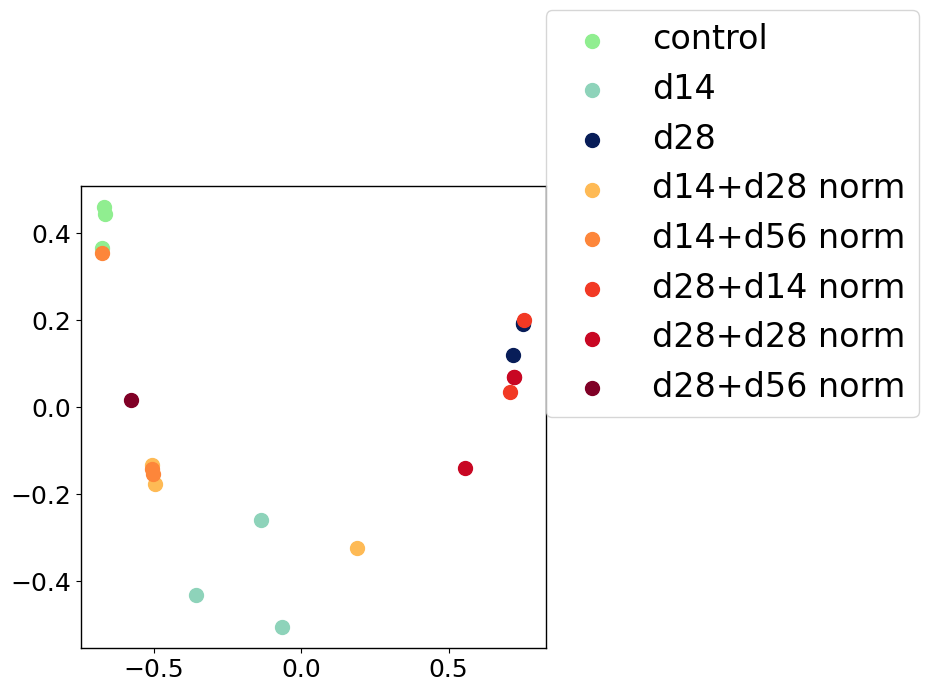

In [31]:
import numpy as np
import matplotlib.cm as cm
import matplotlib.colors as mcolors

legend_order = ['control','d14', 'd28', 'd14+d28 norm','d14+d56 norm',  'd28+d14 norm','d28+d28 norm', 'd28+d56 norm', 
                 ]

disease_categories = ['d14', 'd28']
recovery_categories = ['d14+d28 norm', 'd14+d56 norm', 'd28+d14 norm', 'd28+d28 norm', 'd28+d56 norm']
control_color = 'lightgreen'

def sample_cmap(name, n, vmin=0.35, vmax=1.0):
    cmap = cm.get_cmap(name)
    return [mcolors.to_hex(cmap(v)) for v in np.linspace(vmin, vmax, n)]

disease_colors = dict(zip(disease_categories, sample_cmap('YlGnBu', len(disease_categories))))
recovery_colors = dict(zip(recovery_categories, sample_cmap('YlOrRd', len(recovery_categories))))

color_map = {'control': control_color, **disease_colors, **recovery_colors}
colors = [color_map[cat] for cat in legend_order]


trajectory(spatial_data, colors=colors, label_act=False, font_size=18, knn=10, figsize=(6,6),
           legend_order=legend_order, location_labels=(1, 0.5))


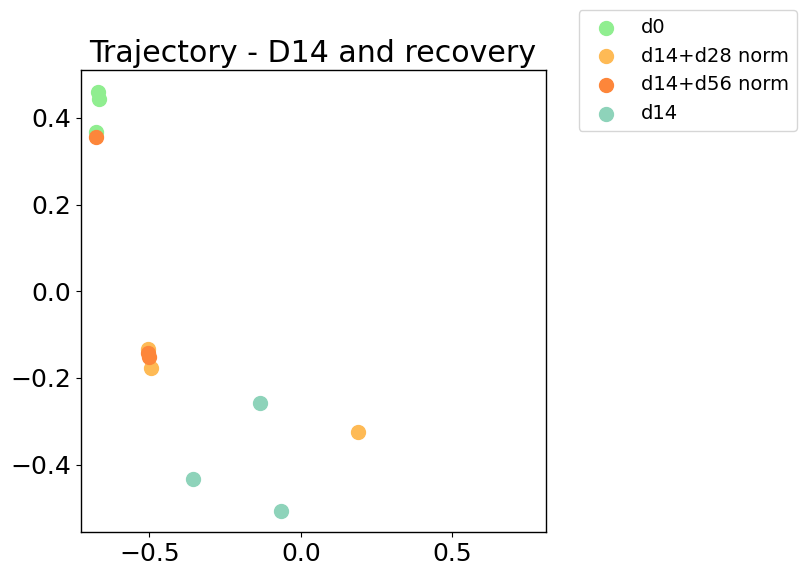

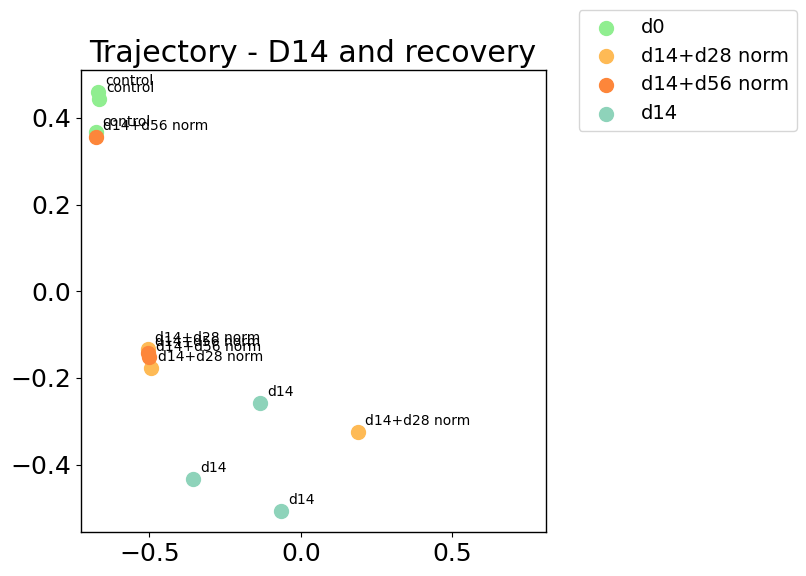

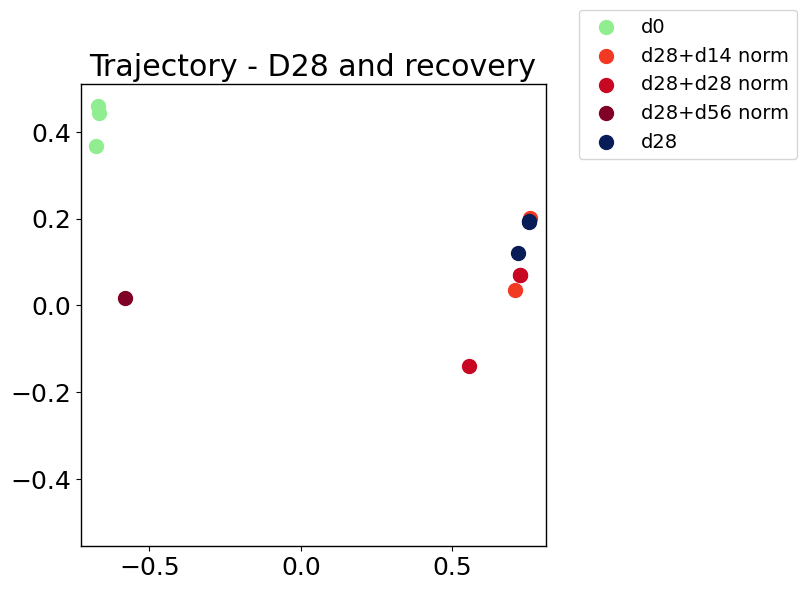

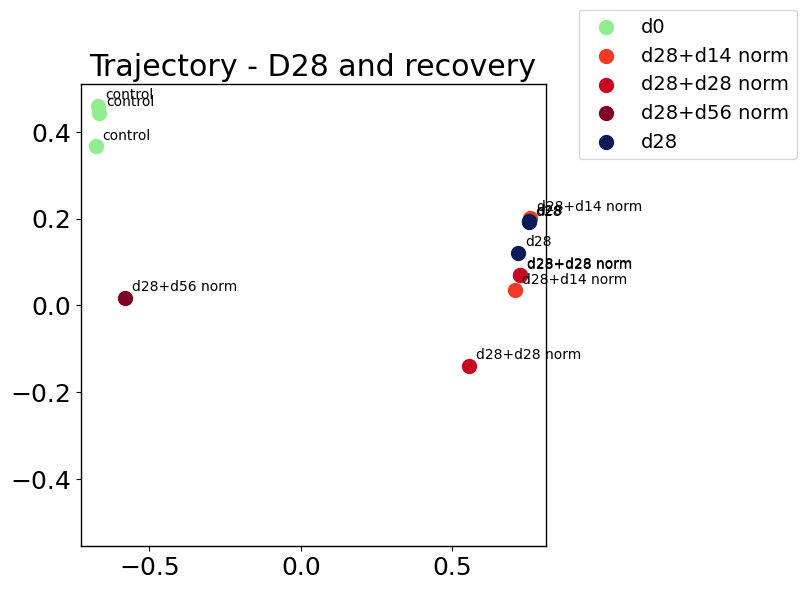

In [116]:

# shared axis limits so both plots are on the same scale
margin = 0.05
xlim = (spatial_data.uns['embedding'][:, 0].min() - margin, spatial_data.uns['embedding'][:, 0].max() + margin)
ylim = (spatial_data.uns['embedding'][:, 1].min() - margin, spatial_data.uns['embedding'][:, 1].max() + margin)

d14_categories = ['control', 'd14+d28 norm', 'd14+d56 norm', 'd14']
d28_categories = ['control', 'd28+d14 norm', 'd28+d28 norm', 'd28+d56 norm', 'd28']

display_labels = {'control': 'd0'}

base_dir = '/beegfs/data/CostaLab/spatial_kidney_kuppelab/Adenin/HE/Results_PILOT/plots/Cells/'

for cats, name in [(d14_categories, 'd14'), (d28_categories, 'd28')]:
    # without point labels
    plot_trajectory_subset(spatial_data, cats, color_map,
                            title=f"Trajectory - {name.upper()} and recovery",
                            path_img=f'{base_dir}/Trajectory_{name}_recovery.pdf',
                            xlim=xlim, ylim=ylim, show_labels=False,
                            display_labels=display_labels, legend_outside=True)

    # with point labels (sampleID beside each point)
    plot_trajectory_subset(spatial_data, cats, color_map,
                            title=f"Trajectory - {name.upper()} and recovery",
                            path_img=f'{base_dir}/Trajectory_{name}_recovery_labeled.pdf',
                            xlim=xlim, ylim=ylim, show_labels=True, label_col='status',
                            display_labels=display_labels, legend_outside=True)

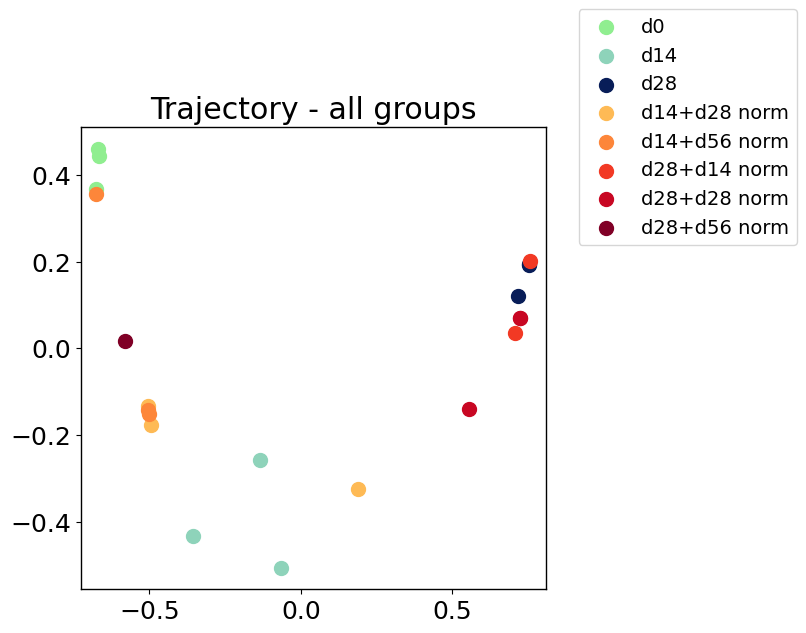

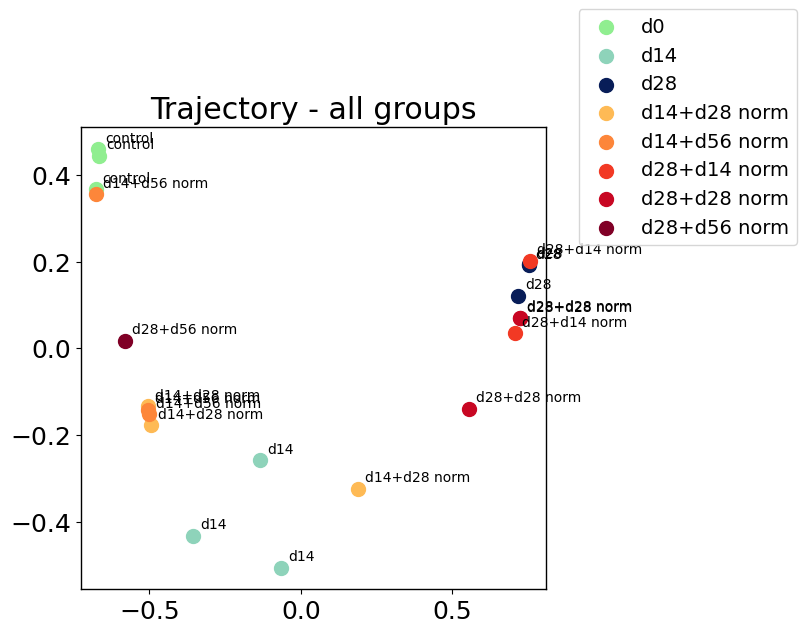

In [117]:
all_categories = ['control','d14','d28', 'd14+d28 norm', 'd14+d56 norm', 
                   'd28+d14 norm', 'd28+d28 norm', 'd28+d56 norm', ]

plot_trajectory_subset(spatial_data, all_categories, color_map,
                        title="Trajectory - all groups",
                        path_img=f'{base_dir}/Trajectory_all_recovery.pdf',
                        xlim=xlim, ylim=ylim, show_labels=False,
                        display_labels=display_labels, legend_outside=True)

# labeled version
plot_trajectory_subset(spatial_data, all_categories, color_map,
                        title="Trajectory - all groups",
                        path_img=f'{base_dir}/Trajectory_all_recovery_labeled.pdf',
                        xlim=xlim, ylim=ylim, show_labels=True, label_col='status',
                        display_labels=display_labels, legend_outside=True)


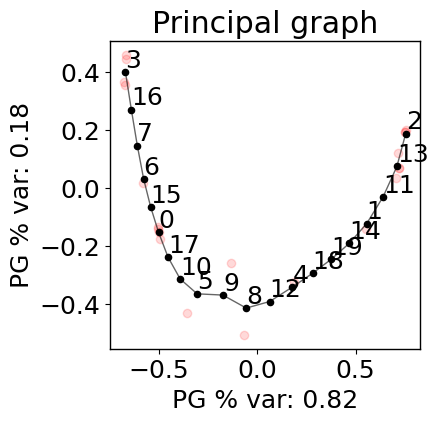

In [32]:
fit_pricipla_graph(spatial_data, source_node =3,figsize=(4,4))

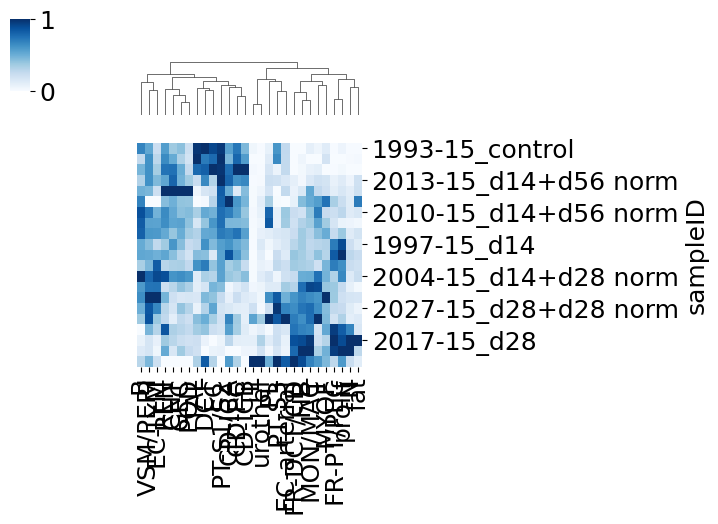

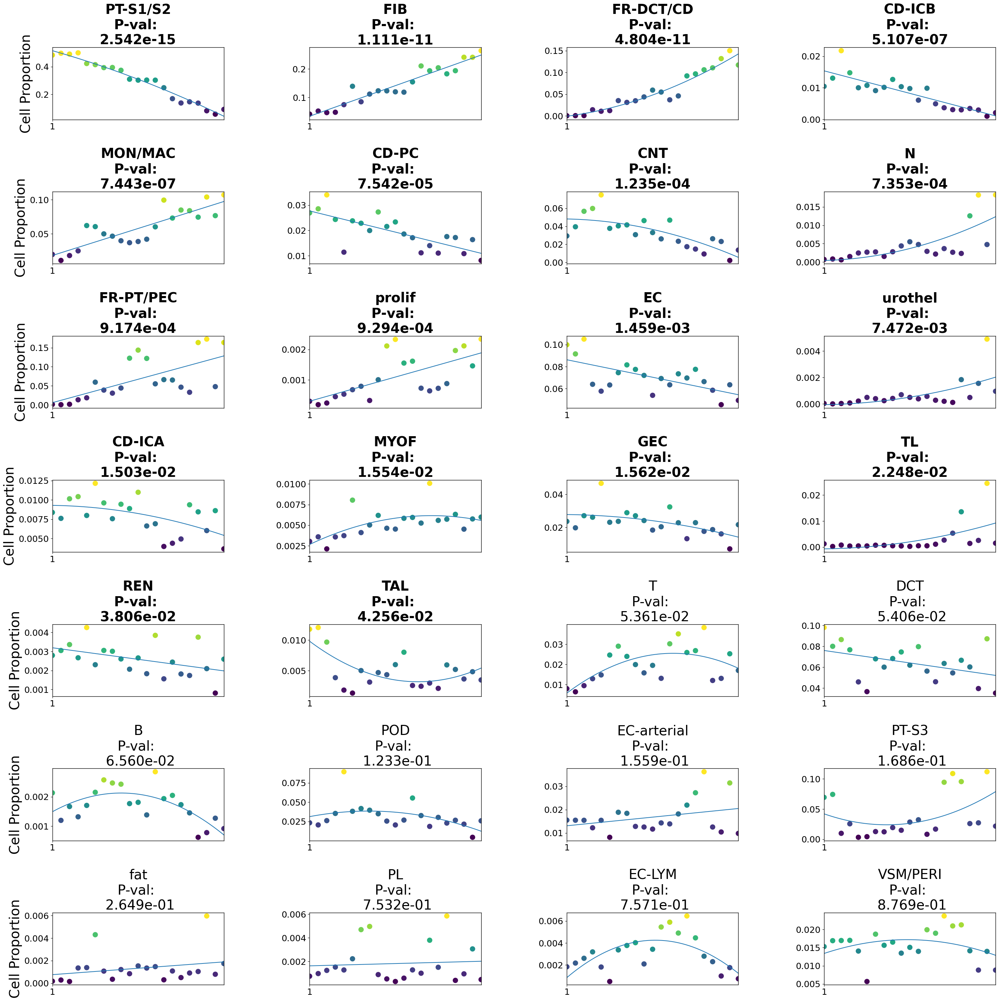

In [35]:
cell_importance(spatial_data,height=35,width=35,fontsize=28,xlim=20,figsize=(4,4))

Saved 21 core plots to cores_annotation_highres_mouse/


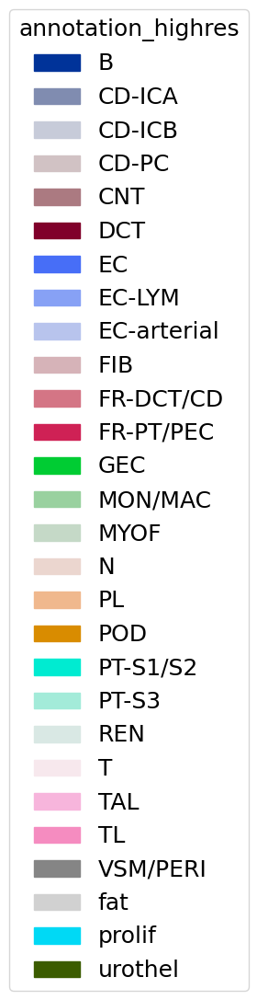

In [33]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

class_color_dict = {
    'B': '#003399', 'CD-ICA': '#808cb0', 'CD-ICB': '#c7cbd9', 'CD-PC': '#d1c2c4',
    'CNT': '#ab7a81', 'DCT': '#80002a', 'EC': '#476ef7', 'EC-LYM': '#87a1f5',
    'EC-arterial': '#b8c4ed', 'FIB': '#d6b3b8', 'FR-DCT/CD': '#d47585',
    'FR-PT/PEC': '#cf2155', 'GEC': '#00cc33', 'MON/MAC': '#99d19f',
    'MYOF': '#c5d9c7', 'N': '#ebd6cf', 'PL': '#f0b88d', 'POD': '#d98c00',
    'PT-S1/S2': '#00ebd1', 'PT-S3': '#a3ebd9', 'REN': '#d9e8e4', 'T': '#f7e8ed',
    'TAL': '#f7b5dc', 'TL': '#f58cc0', 'VSM/PERI': '#858585', 'fat': '#d1d1d1',
    'prolif': '#00d9f5', 'urothel': '#3b5c00'
}

# **Plot each core's cells at their true spatial coordinates, colored by annotation_highres**
cluster_col = "annotation_highres"
core_col = "Donor"  # adjust if spatial_data uses a different column to identify cores
group_col = "group"  # experimental group column
point_size = 10          # cell-level points are much smaller than the 224px patches

output_dir_cells = "cores_annotation_highres_mouse"
os.makedirs(output_dir_cells, exist_ok=True)

coords = spatial_data.obsm["spatial"]
spatial_data.obs[cluster_col] = spatial_data.obs[cluster_col].astype("category")
categories = spatial_data.obs[cluster_col].cat.categories

missing = [c for c in categories if c not in class_color_dict]
if missing:
    print(f"Warning: {len(missing)} categories not in class_color_dict, falling back to gray: {missing}")
color_map = {cat: class_color_dict.get(cat, "#808080") for cat in categories}

for slide_id in spatial_data.obs[core_col].unique():
    mask = (spatial_data.obs[core_col] == slide_id).values
    sub_coords = coords[mask]
    sub_labels = spatial_data.obs.loc[mask, cluster_col]
    group = spatial_data.obs.loc[mask, group_col].iloc[0]  # assumes one group per core

    fig, ax = plt.subplots(figsize=(10, 10))
    fig.patch.set_facecolor("white")
    fig.patch.set_edgecolor("none")
    ax.set_facecolor("white")

    for cat in categories:
        cat_mask = (sub_labels == cat).values
        if cat_mask.sum() == 0:
            continue
        ax.scatter(sub_coords[cat_mask, 0], sub_coords[cat_mask, 1],
                   s=point_size, color=color_map[cat], label=cat, linewidths=0)

    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.axis("off")
    for spine in ax.spines.values():
        spine.set_visible(False)

    fig.tight_layout()
    fig.savefig(os.path.join(output_dir_cells, f"{slide_id}_{group}.pdf"),
                dpi=200, bbox_inches="tight", facecolor="white", edgecolor="none")
    plt.close(fig)

print(f"Saved {spatial_data.obs[core_col].nunique()} core plots to {output_dir_cells}/")

# **Save the annotation_highres legend separately**
fig, ax = plt.subplots(figsize=(3, len(categories) * 0.3))
fig.patch.set_facecolor("white")
legend_handles = [mpatches.Patch(color=color_map[c], label=c) for c in categories]
ax.legend(handles=legend_handles, title=cluster_col, loc="center")
ax.axis("off")
fig.tight_layout()
fig.savefig(os.path.join(output_dir_cells, f"_legend_{cluster_col}.pdf"),
            dpi=200, bbox_inches="tight", facecolor="white", edgecolor="none")
plt.show()


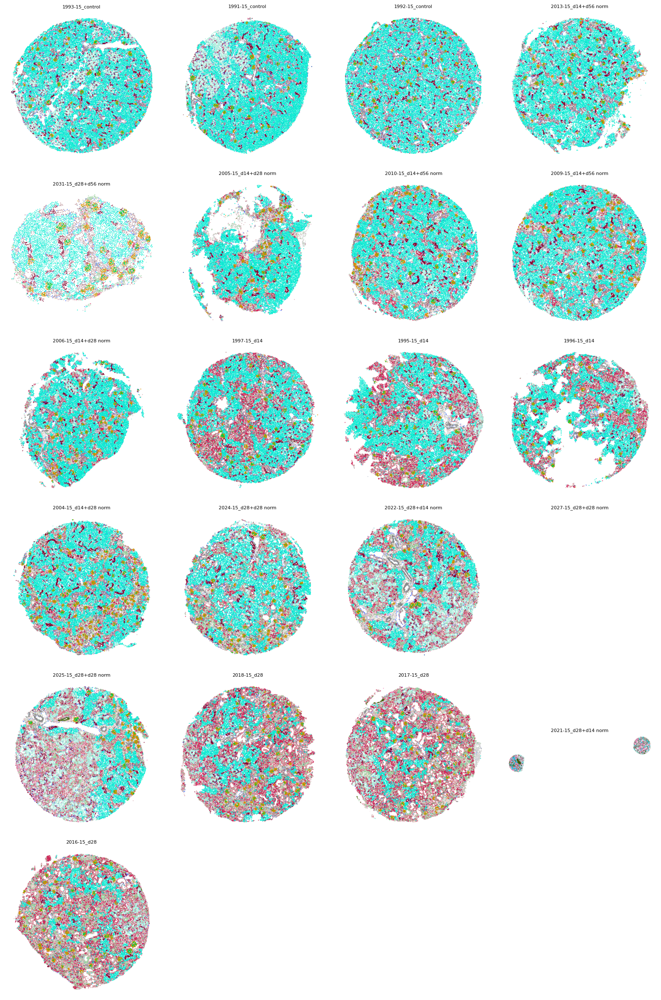

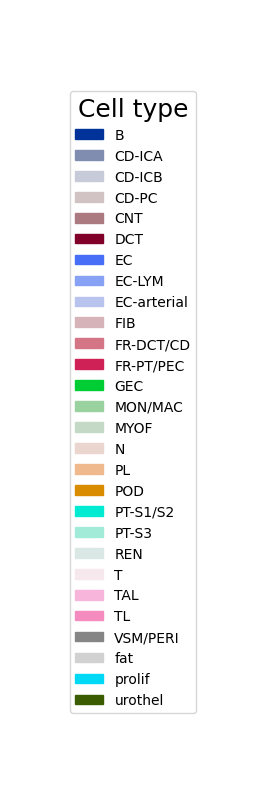

In [36]:
class_color_dict = {
    'B': '#003399', 'CD-ICA': '#808cb0', 'CD-ICB': '#c7cbd9', 'CD-PC': '#d1c2c4',
    'CNT': '#ab7a81', 'DCT': '#80002a', 'EC': '#476ef7', 'EC-LYM': '#87a1f5',
    'EC-arterial': '#b8c4ed', 'FIB': '#d6b3b8', 'FR-DCT/CD': '#d47585',
    'FR-PT/PEC': '#cf2155', 'GEC': '#00cc33', 'MON/MAC': '#99d19f',
    'MYOF': '#c5d9c7', 'N': '#ebd6cf', 'PL': '#f0b88d', 'POD': '#d98c00',
    'PT-S1/S2': '#00ebd1', 'PT-S3': '#a3ebd9', 'REN': '#d9e8e4', 'T': '#f7e8ed',
    'TAL': '#f7b5dc', 'TL': '#f58cc0', 'VSM/PERI': '#858585', 'fat': '#d1d1d1',
    'prolif': '#00d9f5', 'urothel': '#3b5c00'
}

plot_sample_grid_by_celltype(
    adata=spatial_data,
    order_df=spatial_data.uns['orders'],
    color_dict=class_color_dict,
    cell_col='annotation_highres',
    sample_col='sample_',
    sample_id_col_in_order='sampleID',
    ncols=4,
    save_path='/beegfs/data/CostaLab/spatial_kidney_kuppelab/Adenin/HE/Results_PILOT/plots/Cells/cores_grid_celltype.pdf',
)

save_celltype_legend(
    class_color_dict,
    save_path='/beegfs/data/CostaLab/spatial_kidney_kuppelab/Adenin/HE/Results_PILOT/plots/Cells/cores_grid_celltype_legend.pdf',
)


In [125]:
#spatial_data.uns['orders'].rename(columns={'Time_score': 'pseudotime'}, inplace=True)
#create_sample_grid(df=spatial_data.uns['orders'],image_dir='cores_annotation_highres_mouse/', output_path="Results_PILOT/cores_annotation_highres_mouse_ordered.pdf",zoom=0.06)

In [40]:
def assign_leiden_to_cells(spatial_data, adata, patch_size=224,
                            cluster_col='leiden_04', sample_col_spatial='sample_',
                            sample_col_patches='sample_', coord_col='spatial_transformed'):
    patch_labels = np.full(spatial_data.n_obs, 'not_assigned', dtype=object)

    for sample_id in spatial_data.obs[sample_col_spatial].unique():
        obs_patches = adata.obs[adata.obs[sample_col_patches] == sample_id]
        if len(obs_patches) == 0:
            print(f"Warning: no patches found for sample {sample_id!r}")
            continue

        cell_mask = (spatial_data.obs[sample_col_spatial] == sample_id).values
        coords = spatial_data.obsm[coord_col][cell_mask]

        # grid offset in case patches don't start exactly at 0 for this sample
        x_offset = obs_patches['X'].min() % patch_size
        y_offset = obs_patches['Y'].min() % patch_size

        patch_lookup = {
            (row.X, row.Y): getattr(row, cluster_col)
            for row in obs_patches.itertuples()
        }

        bin_x = ((coords[:, 0] - x_offset) // patch_size) * patch_size + x_offset
        bin_y = ((coords[:, 1] - y_offset) // patch_size) * patch_size + y_offset

        labels = [patch_lookup.get(k, 'not_assigned') for k in zip(bin_x, bin_y)]
        patch_labels[cell_mask] = labels

    return patch_labels


spatial_data.obs['patch_label'] = assign_leiden_to_cells(spatial_data, adata)

n_assigned = (spatial_data.obs['patch_label'] != 'not_assigned').sum()
print(f"{n_assigned}/{spatial_data.n_obs} cells assigned to a patch label ({spatial_data.n_obs - n_assigned} not_assigned)")


712244/787964 cells assigned to a patch label (75720 not_assigned)


In [47]:
spatial_data.obs['patch_annotation'] = spatial_data.obs['patch_label']

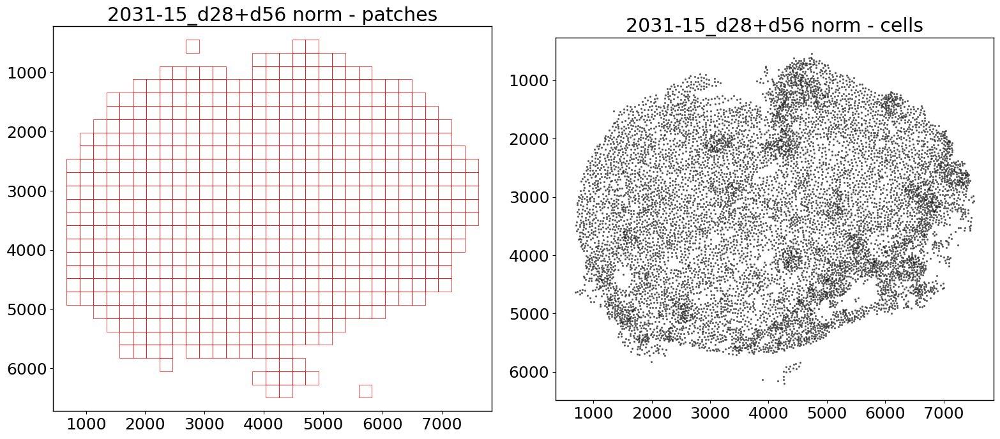

In [48]:
from matplotlib.patches import Rectangle
def plot_cells_and_patches_split(spatial_data, adata, sample_id, patch_size=224,
                                  sample_col_spatial='sample_', sample_col_patches='sample_',
                                  coord_col='spatial_transformed', n_cells=20000, figsize=(16, 8)):
    obs_patches = adata.obs[adata.obs[sample_col_patches] == sample_id]
    cell_mask = (spatial_data.obs[sample_col_spatial] == sample_id).values
    coords = spatial_data.obsm[coord_col][cell_mask]

    if len(coords) > n_cells:
        idx = np.random.choice(len(coords), n_cells, replace=False)
        coords = coords[idx]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)

    # left: patches only, own auto-scaled axes
    for row in obs_patches.itertuples():
        ax1.add_patch(Rectangle((row.X, row.Y), patch_size, patch_size,
                                 facecolor='none', edgecolor='red', linewidth=0.5))
    ax1.set_xlim(obs_patches['X'].min() - patch_size, obs_patches['X'].max() + 2 * patch_size)
    ax1.set_ylim(obs_patches['Y'].min() - patch_size, obs_patches['Y'].max() + 2 * patch_size)
    ax1.set_aspect('equal')
    ax1.invert_yaxis()
    ax1.set_title(f"{sample_id} - patches")

    # right: cells only, own auto-scaled axes
    ax2.scatter(coords[:, 0], coords[:, 1], s=2, color='black', alpha=0.5)
    ax2.set_aspect('equal')
    ax2.invert_yaxis()
    ax2.set_title(f"{sample_id} - cells")

    plt.tight_layout()
    plt.show()


sample_id = '2031-15_d28+d56 norm'
plot_cells_and_patches_split(spatial_data, adata, sample_id)


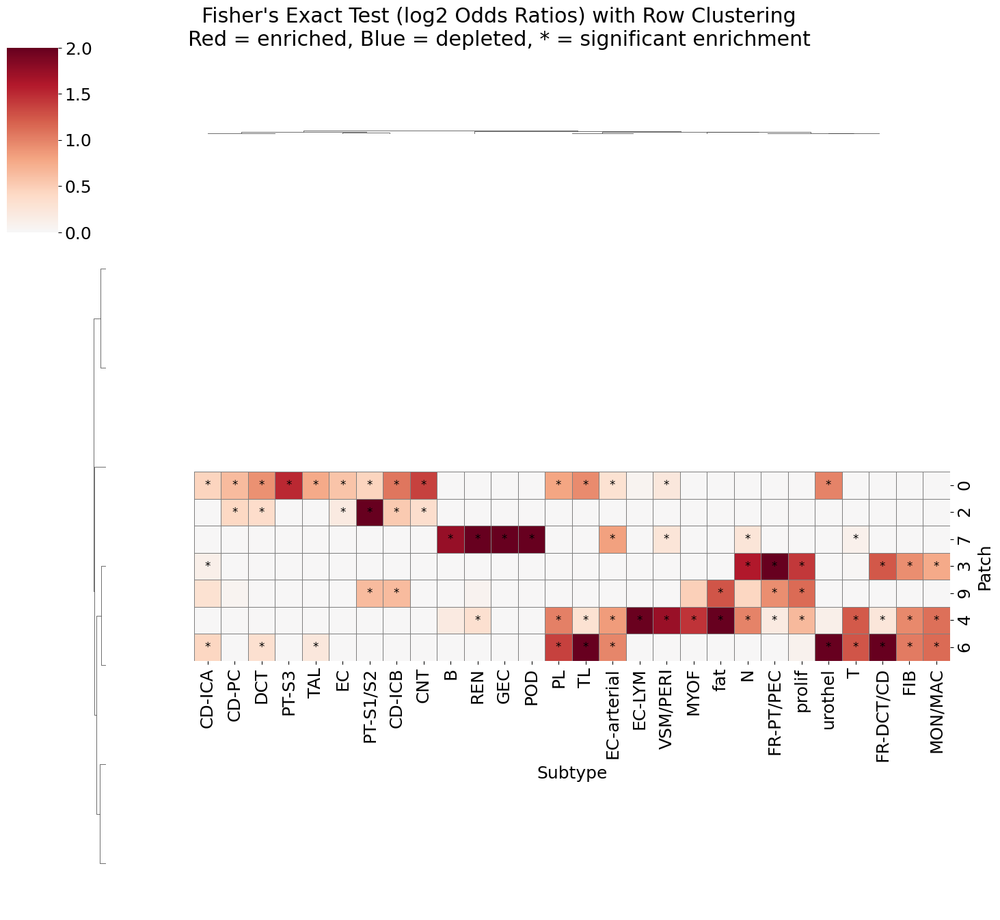

Original patches: 7
Filtered patches (with significance): 7
Original cell subtypes: 28
Filtered cell subtypes (with enrichment): 28


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
spatial_data_=spatial_data[~spatial_data.obs['patch_annotation'].isin(['not_assigned'])].copy()
patches = spatial_data_.obs["patch_annotation"].unique()
subtypes = spatial_data_.obs["annotation_highres"].unique()

results = []

# Fisher's Exact Test per patch × cell type
for patch in patches:
    for subtype in subtypes:
        in_patch = spatial_data_.obs["patch_annotation"] == patch
        is_subtype = spatial_data_.obs["annotation_highres"] == subtype

        a = ((in_patch) & (is_subtype)).sum()
        b = ((in_patch) & (~is_subtype)).sum()
        c = ((~in_patch) & (is_subtype)).sum()
        d = ((~in_patch) & (~is_subtype)).sum()

        oddsratio, p = fisher_exact([[a, b],[c, d]])
        results.append((patch, subtype, a, oddsratio, p))

# DataFrame
fisher_df = pd.DataFrame(results, columns=["Patch","Subtype","Count","OddsRatio","p_value"])
fisher_df["p_adj"] = multipletests(fisher_df["p_value"], method="fdr_bh")[1]

# Pivot matrices
odds_mat = fisher_df.pivot(index="Patch", columns="Subtype", values="OddsRatio")
pval_mat = fisher_df.pivot(index="Patch", columns="Subtype", values="p_adj")

# Log2 transform & clip
log2_odds = np.log2(odds_mat + 1e-6)

# Filtering step: Remove cells that are only significant for depletion
# and patches that have no significant enrichment

# 1. Identify significant enrichments (log2_odds > 0 AND p_adj < 0.05)
significant_enrichments = (log2_odds > 0) & (pval_mat < 0.05)

# 2. Identify significant depletions (log2_odds < 0 AND p_adj < 0.05)
significant_depletions = (log2_odds < 0) & (pval_mat < 0.05)

# 3. Filter cell subtypes: keep only those with at least one significant enrichment
subtypes_with_enrichment = significant_enrichments.any(axis=0)
filtered_subtypes = subtypes_with_enrichment[subtypes_with_enrichment].index.tolist()

# 4. Filter patches: keep only those with at least one significant result (enrichment OR depletion)
patches_with_significance = (significant_enrichments | significant_depletions).any(axis=1)
filtered_patches = patches_with_significance[patches_with_significance].index.tolist()

# Apply filtering
filtered_log2_odds = log2_odds.loc[filtered_patches, filtered_subtypes]
filtered_pval_mat = pval_mat.loc[filtered_patches, filtered_subtypes]

# Create clustermap with filtered data
cg = sns.clustermap(
    filtered_log2_odds,
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    linecolor="gray",
    figsize=(15,15),
    row_cluster=True,
    col_cluster=True,
    vmin=0,
    vmax=2,
    metric="correlation",   # alternative: "euclidean", "cityblock", "cosine", etc.
)
for ax in [cg.ax_row_dendrogram, cg.ax_col_dendrogram, cg.ax_heatmap]:
    ax.set_aspect('equal')
# Add stars manually for significant ENRICHMENTS only (no stars for depletions)
ax = cg.ax_heatmap

# Get the reordered indices from clustering
reordered_row_indices = cg.dendrogram_row.reordered_ind
reordered_col_indices = cg.dendrogram_col.reordered_ind

# Get the actual reordered patch and subtype names
reordered_patches = filtered_log2_odds.index[reordered_row_indices]
reordered_subtypes = filtered_log2_odds.columns[reordered_col_indices]

# Iterate through the reordered positions
for i, patch in enumerate(reordered_patches):
    for j, subtype in enumerate(reordered_subtypes):
        # Only add star if: significant AND enriched (log2_odds > 0)
        if (filtered_pval_mat.loc[patch, subtype] < 0.05) and (filtered_log2_odds.loc[patch, subtype] > 0):
            ax.text(j + 0.5, i + 0.5, "*", color="black", ha="center", va="center", fontsize=12)

plt.suptitle("Fisher's Exact Test (log2 Odds Ratios) with Row Clustering\nRed = enriched, Blue = depleted, * = significant enrichment", y=1.02)
plt.savefig("Fisher_Exact_Test_filtered.pdf")
plt.show()

# Optional: Print filtering summary
print(f"Original patches: {len(patches)}")
print(f"Filtered patches (with significance): {len(filtered_patches)}")
print(f"Original cell subtypes: {len(subtypes)}")
print(f"Filtered cell subtypes (with enrichment): {len(filtered_subtypes)}")

In [20]:
import os
import numpy as np
import matplotlib.pyplot as plt

def plot_sample_grid_by_celltype(
    adata,
    order_df,
    color_dict,
    cell_col='annotation_highres',
    sample_col='sample_ID_1',
    sample_id_col_in_order='sampleID',   # column in order_df with the sample IDs, in the order you want plotted
    title_col_in_order=None,             # optional extra column in order_df (e.g. 'status') appended to each panel's title
    ncols=4,                             # samples per row — editable
    point_size=2,
    panel_size=(4, 4),
    save_path='cores_grid.pdf',
):
    coords = adata.obsm['spatial_transformed']
    sample_order = order_df[sample_id_col_in_order].tolist()
    n_samples = len(sample_order)
    nrows = int(np.ceil(n_samples / ncols))

    fig, axes = plt.subplots(nrows, ncols,
                              figsize=(panel_size[0] * ncols, panel_size[1] * nrows))
    axes = np.array(axes).reshape(-1)

    for i, sample_id in enumerate(sample_order):
        ax = axes[i]
        mask = (adata.obs[sample_col] == sample_id).values
        sub_coords = coords[mask]
        sub_labels = adata.obs.loc[mask, cell_col]

        for cat, color in color_dict.items():
            cat_mask = (sub_labels == cat).values
            if cat_mask.sum() == 0:
                continue
            ax.scatter(sub_coords[cat_mask, 0], sub_coords[cat_mask, 1],
                       s=point_size, color=color, linewidths=0)

        title = str(sample_id)
        if title_col_in_order is not None:
            title = f"{title}_{order_df.iloc[i][title_col_in_order]}"

        ax.invert_yaxis()
        ax.set_aspect('equal')
        ax.axis('off')
        ax.set_title(title, fontsize=8)

    # hide unused panels if n_samples isn't a multiple of ncols
    for j in range(n_samples, len(axes)):
        axes[j].axis('off')

    fig.tight_layout()
    out_dir = os.path.dirname(save_path)
    if out_dir:
        os.makedirs(out_dir, exist_ok=True)
    fig.savefig(save_path, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def save_celltype_legend(color_dict, save_path='cores_grid_legend.pdf', fontsize=10):
    import matplotlib.patches as mpatches
    legend_elements = [mpatches.Patch(color=color, label=cat) for cat, color in color_dict.items()]

    fig, ax = plt.subplots(figsize=(3, len(color_dict) * 0.3))
    ax.legend(handles=legend_elements, loc='center', fontsize=fontsize, title='Cell type')
    ax.axis('off')
    fig.tight_layout()
    out_dir = os.path.dirname(save_path)
    if out_dir:
        os.makedirs(out_dir, exist_ok=True)
    fig.savefig(save_path, bbox_inches='tight')
    plt.show()
    plt.close(fig)


In [24]:
def trajectory(adata, n_evecs=2, epsilon=1, alpha=0.5, knn=64, sample_col=1, 
               clusters='status', label_act=False, colors=['#377eb8', '#ff7f00', '#e41a1c'],
               legend_order=None, legend_outside=False, location_labels='center', 
               figsize=(12,12), font_size=24, axes_line_width=1, axes_color='black',
               facecolor='white', point_size=100, cmap='viridis', fontsize_legend=24,
               alpha_trans=1, plot_title=" "):
    
    """
    Find trajectories using Diffusion Maps and visualize the trajectory plot.

    Parameters
    ----------
    adata : AnnData
        Annotated data matrix containing EMD, annotations, and other necessary data.
    n_evecs : int, optional
        Number of embedding vectors, by default 2.
    epsilon : float or str, optional
        Method for choosing the epsilon in diffusion maps, by default 1.
    alpha : float, optional
        Normalization parameter in the bandwidth function, by default 0.5.
    knn : int, optional
        Number of nearest neighbors for constructing the kernel, by default 64.
    sample_col : int, optional
        Index of the column representing sample IDs in annotation data, by default 1.
    clusters : str, optional
        Name of the column representing clusters/categories in annotation data, by default 'status'.
    label_act : bool, optional
        Whether to label data points with sample IDs, by default False.
    colors : list, optional
        List of colors for different categories, by default ['#377eb8', '#ff7f00', '#e41a1c'].
    legend_order : list, optional
        List specifying the order of categories in legend, by default None.
    legend_outside : bool, optional
        Whether to place legend outside the plot, by default False.
    location_labels : str, optional
        Location of the legend labels when inside plot, by default 'center'.
    figsize : tuple, optional
        figsize, by default (12,12).
    font_size : int, optional
        Font size for labels and annotations, by default 24.
    axes_line_width : float, optional
        Line width of the axes, by default 1.
    axes_color : str, optional
        Color of the axes lines, by default 'black'.
    facecolor : str, optional
        Background color of the figure, by default 'white'.
    point_size : int, optional
        Size of the data points in the plot, by default 100.
    cmap : str, optional
        Colormap for scatter plot, by default 'viridis'.
    fontsize_legend : int, optional
        Font size of the legend, by default 24.
    alpha_trans : float, optional
        Transparency level for data points, by default 1.
    plot_title : str, optional
        Title of the plot, by default "Trajectory of the disease progression".

    Returns
    -------
    None
        Visualizes and saves the trajectory plot.
    """
    
    import os
    import matplotlib.pyplot as plt
    from matplotlib import cycler
    import numpy as np
    import pandas as pd
    
    EMD = adata.uns['EMD'] / adata.uns['EMD'].max()
    df = adata.uns['annot']
    
    path = 'Results_PILOT/plots'
    
    if not os.path.exists(path):
        os.makedirs(path)
    
    # استفاده از colors برای custom_cycler
    custom_cycler = (cycler(color=colors))
    
    mydmap = diffusion_map.DiffusionMap.from_sklearn(n_evecs=n_evecs, epsilon=epsilon, 
                                                      alpha=alpha, k=knn)
    embedding = mydmap.fit_transform(EMD)
    
    plt.rcParams.update({'font.size': font_size})
    plt.rcParams["axes.edgecolor"] = axes_color
    plt.rcParams["axes.linewidth"] = axes_line_width
    
    df = df.drop_duplicates(subset=[df.columns[sample_col]])
    
    # تعیین اندازه figure با توجه به موقعیت legend
    if legend_outside:
        fig = plt.figure(figsize=(figsize[0] + 2, figsize[1]))
    else:
        fig = plt.figure(figsize=figsize)
    
    ax = plt.gca()
    ax.set(facecolor=facecolor)
    ax.set_prop_cycle(custom_cycler)
    
    # تعیین ترتیب categories
    categories = df[clusters].unique()
    if legend_order is not None:
        # فقط categories موجود در legend_order را نگه می‌داریم
        categories = [cat for cat in legend_order if cat in categories]
        # اضافه کردن categories که در legend_order نیستند به انتها
        remaining_cats = [cat for cat in df[clusters].unique() if cat not in legend_order]
        categories.extend(remaining_cats)
    
    # رسم داده‌ها با ترتیب مشخص شده
    handles = []
    labels = []
    
    for category in categories:
        aux = np.array(df[clusters] == category)
        group_data = embedding[aux]
        
        # اطمینان از اینکه حداقل یک نقطه برای این category وجود دارد
        if len(group_data) > 0:
            scatter = ax.scatter(group_data[:, 0], group_data[:, 1], 
                                alpha=alpha_trans, label=category, 
                                cmap=cmap, s=point_size)
            handles.append(scatter)
            labels.append(category)
            
            if label_act:
                names = np.array(df[df[clusters] == category].sampleID)
                for k, txt in enumerate(names):
                    ax.annotate(txt, (group_data[k, 0], group_data[k, 1]), 
                              fontsize=font_size)
    
    # تنظیم موقعیت legend
    if legend_outside:
        # قرار دادن legend در بیرون plot
        ax.legend(handles, labels, loc='center left', 
                 fontsize=fontsize_legend, bbox_to_anchor=(1, 0.5))
        # تنظیم margins برای جا دادن legend
        plt.subplots_adjust(right=0.85)
    else:
        ax.legend(handles, labels, loc=location_labels, fontsize=fontsize_legend)
    
    plt.title(plot_title)
    plt.savefig(path + "/" + plot_title + '.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)
    
    adata.uns['embedding'] = embedding


def plot_umap_and_stacked_bar(
    adata, 
    cell_type_col, 
    component_col='component_assignment', 
    palette_name=None, 
    title="Cell Type vs Component Assignment", 
    xlabel="Component Assignment", 
    ylabel="Proportion", 
    save_path='figures/Bar_plot.png', 
    umap_save_name="_components_vs_cell_types.png", 
    umap_size=5, 
    umap_legend_fontsize=10, 
    umap_ncols=2, 
    umap_wspace=0.55, 
    bar_figsize=(14, 8), 
    umap_figsize=(10, 10), 
    axes_titlesize=18, 
    axes_labelsize=16, 
    legend_fontsize=14, 
    legend_bbox_to_anchor=(1.05, 1), 
    legend_loc='upper left', 
    legend_borderaxespad=0.0
):
    """
    Plots a UMAP and a normalized stacked bar chart of component assignments vs. cell types.

    Parameters:
        adata: Input AnnData object.
        cell_type_col (str): Name of the column containing cell type annotations.
        component_col (str): Name of the column containing component assignments.
        palette_name (str, optional): Name of the palette or a custom palette list to use for coloring.
        title (str, optional): Title of the plot.
        xlabel (str, optional): Label for the x-axis.
        ylabel (str, optional): Label for the y-axis.
        save_path (str, optional): File path to save the bar plot (PDF or PNG). If None, the plot is not saved.
        umap_save_name (str, optional): File name for saving the UMAP plot.
        umap_size (int, optional): Point size for the UMAP plot.
        umap_legend_fontsize (int, optional): Font size for the UMAP legend.
        umap_ncols (int, optional): Number of columns for the UMAP plots.
        umap_wspace (float, optional): Width space between UMAP plots.
        bar_figsize (tuple, optional): Figure size for the bar plot.
        umap_figsize (tuple, optional): Figure size for the UMAP plot.
        axes_titlesize (int, optional): Font size for axes titles.
        axes_labelsize (int, optional): Font size for axes labels.
        legend_fontsize (int, optional): Font size for the legend.
        legend_bbox_to_anchor (tuple, optional): Anchor position for the legend.
        legend_loc (str, optional): Location of the legend.
        legend_borderaxespad (float, optional): Padding between legend and axes border.

    Returns:
        None
    """
    # Ensure component_col is treated as a string
    #adata.obs[component_col] = adata.obs[component_col].astype(str)

    # Set default palette if none is provided
    adata.obs['component_assignment'] = adata.obs['component_assignment'].astype(str)
    if palette_name is None:
        palette = sns.color_palette("Set1", 9) + sns.color_palette("Set2", 8) + sns.color_palette("Set3", 12) + sns.color_palette("Dark2", 4)
        palette = palette[:33]  # Limit the palette to exactly 33 colors
    else:
        palette = palette_name

    # Plot UMAP
    sc.pl.umap(
        adata,
        color=[component_col, cell_type_col],
        save=umap_save_name,  
        ncols=umap_ncols, 
        wspace=umap_wspace, 
        legend_fontsize=umap_legend_fontsize, 
        size=umap_size, 
        palette=palette
    )

    # Set font properties globally
    plt.rc('axes', titlesize=axes_titlesize)  # Set font size for axes titles
    plt.rc('axes', labelsize=axes_labelsize)  # Set font size for axes labels
    plt.rc('legend', fontsize=legend_fontsize)  # Set font size for legend

    # Prepare data for the stacked bar plot
    df = pd.DataFrame({
        'component_assignment': adata.obs[component_col],
        'Cell Type': adata.obs[cell_type_col]
    })

    # Create a cross-tab to get counts (no normalization)
    cross_tab = pd.crosstab(df[component_col], df['Cell Type'])

    # Normalize each row to ensure bars have the same total length
    cross_tab_normalized = cross_tab.div(cross_tab.sum(axis=1), axis=0)

    # Plot as a stacked bar plot using the custom palette (with normalization)
    plt.figure(figsize=bar_figsize)  # Use dynamic figure size for bar plot
    ax = cross_tab_normalized.plot(kind='bar', stacked=True, color=palette[:33], figsize=bar_figsize)

    # Add labels and titles
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)

    # Move legend to the right side of the plot
    plt.legend(
        title='Cell Type', 
        bbox_to_anchor=legend_bbox_to_anchor, 
        loc=legend_loc, 
        borderaxespad=legend_borderaxespad
    )

    # Save the plot as a file if save_path is provided
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')

    # Show the plot
    plt.tight_layout()
    plt.show()


In [25]:

import scanpy as sc
#from pilot_gm_vae import *



from matplotlib.offsetbox import OffsetImage, AnnotationBbox
def create_sample_grid(df, image_dir='/data/scRNA/To_Mehdi/pan_data/xei/Human/colored_patches_cluters_/', output_path="Results_PILOT/Histology_figures/sample_grid_cores.png",zoom=0.15,num_rows = 10):
    """
    Create a grid of sample images based on ordering in a DataFrame.
    
    Args:
        df: DataFrame containing at least:
            - 'sampleID': unique sample identifiers
            - 'order': numerical ordering for sorting
        image_dir: Directory containing images (named as {sampleID}.png)
        output_path: Where to save the resulting grid
    """
    # Sort samples by the specified order
    sorted_df = df.sort_values('pseudotime')
    sample_names = sorted_df['sampleID'].tolist()
    
    # Calculate grid dimensions (10 rows, auto columns)
    num_samples = len(sample_names)
    num_rows = num_rows
    num_cols = math.ceil(num_samples / num_rows)
    
    # Prepare figure
    fig, axes = plt.subplots(num_rows, num_cols, 
                           figsize=(num_cols * 2, num_rows * 2))
    axes = axes.flatten()
    
    # Image loading function
    def get_image(path, zoom=zoom):
        if os.path.exists(path):
            return OffsetImage(plt.imread(path), zoom=zoom)
        return None
    
    # Plot each sample
    for i, sample in enumerate(sample_names):
        img_path = os.path.join(image_dir, f"{sample}.png")
        ax = axes[i]
        
        # Add image if exists
        img = get_image(img_path)
        if img:
            ab = AnnotationBbox(img, (0.5, 0.5), 
                              frameon=False, 
                              box_alignment=(0.5, 0.5))
            ax.add_artist(ab)
        
        # Minimal labeling
        ax.set_title(sample, fontsize=6)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.axis('off')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
    
    # Hide unused subplots
    for i in range(num_samples, len(axes)):
        axes[i].axis('off')
    
    
    
    plt.tight_layout()
    fig.canvas.draw()  # Force render
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f"Saved grid to {output_path}")
